<a href="https://colab.research.google.com/github/julia-zhmurko/JuliaZhmurko-ML/blob/main/%D0%A2%D1%80%D0%B5%D0%BD%D1%83%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D1%96_%D0%BD%D0%BE%D1%83%D1%82%D0%B1%D1%83%D0%BA%D0%B8_%D0%B4%D0%BE_%D0%BB%D0%B5%D0%BA%D1%86%D1%96%D0%B9/%D0%96%D0%BC%D1%83%D1%80%D0%BA%D0%BE_%D0%AE%D0%BB%D1%96%D1%8F_%D0%A4%D0%86%D0%A2_4_10_%D0%9B%D0%B5%D0%BA%D1%86%D1%96%D1%8F_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%9C%D0%9D_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тренувальний ноутбук до лекції «Кластеризація даних у машинному навчанні»

**Дисципліна:** Машинне навчання  
**Формат:** практична демонстрація теоретичних положень лекції; Python / Jupyter Notebook / Google Colab.

**Мета:** навчитися готувати ознаки, застосовувати основні алгоритми кластеризації, обґрунтовано визначати кількість кластерів, оцінювати результати й інтерпретувати їх.

**Що буде розглянуто:**
1. Метрики відстані, стандартизація та PCA.
2. K-means, MiniBatchKMeans, BisectingKMeans.
3. Вибір $K$: лікоть, силует, Calinski–Harabasz, Davies–Bouldin, `KneeLocator` та `KElbowVisualizer`.
4. Агломеративна кластеризація та дендрограма.
5. DBSCAN, OPTICS, HDBSCAN і визначення щільнісних груп.
6. Mean Shift, Affinity Propagation, BIRCH, Spectral Clustering.
7. Gaussian Mixture Models, AIC/BIC і BayesianGaussianMixture.
8. Наскрізний аналіз Wine, перевірка якості та інтерпретація сегментів.
9. **Одне самостійне завдання** наприкінці.

> Усі основні приклади працюють на вбудованих наборах даних `scikit-learn`; зовнішні CSV-файли не потрібні. Дані про опосумів із лабораторної роботи **не використовуються**. Для відтворюваності застосовуємо `random_state=42`.

**Виконала:** студентка групи ФІТ 4-10 Жмурко Юлія Андріївна

**Була присутня на парі (03.11.2026)**

## 0. Середовище та імпорт бібліотек

**Відповідність лекції:** розділи 2, 3, 8, 11. У Google Colab достатньо послідовно виконати комірки. Для більшості демонстрацій потрібні лише `numpy`, `pandas`, `matplotlib`, `scipy` та `scikit-learn`.

*Окремо:* `kneed` і `yellowbrick` — додаткові пакети, а не вбудовані функції `scikit-learn`. Їхні демонстрації не перериватимуть виконання ноутбука, якщо пакети ще не встановлені.

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import scipy

from sklearn.datasets import load_iris, load_wine, make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import (
    KMeans, MiniBatchKMeans, BisectingKMeans,
    AgglomerativeClustering, DBSCAN, OPTICS, HDBSCAN,
    MeanShift, estimate_bandwidth, AffinityPropagation,
    Birch, SpectralClustering,
)
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, adjusted_mutual_info_score,
)
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import euclidean, cityblock, cosine

RANDOM_STATE = 42
pd.set_option('display.max_columns', 15)
plt.rcParams.update({'figure.figsize': (8, 5), 'axes.grid': True,
                     'grid.alpha': 0.20, 'font.size': 10})

print('scikit-learn:', sklearn.__version__)
print('NumPy:', np.__version__)
print('SciPy:', scipy.__version__)

scikit-learn: 1.6.1
NumPy: 2.4.6
SciPy: 1.16.3


###**Пояснення:**

На початковому етапі роботи імпортуємо необхідні бібліотеки та модулі Python, які використовуватимуться для підготовки даних, реалізації алгоритмів кластеризації, оцінювання якості отриманих результатів та їх візуалізації.

Основні бібліотеки та їх призначення:

- **NumPy (`numpy`)** – виконання числових обчислень та робота з багатовимірними масивами.

- **Pandas (`pandas`)** – опрацювання, аналіз і представлення даних у табличному форматі.

- **Matplotlib (`matplotlib.pyplot`)** – побудова графіків та візуалізація результатів кластеризації.

- **Scikit-learn (`sklearn`)** – використання вбудованих наборів даних, алгоритмів кластеризації, методів попередньої обробки та метрик оцінювання якості.

- **SciPy (`scipy`)** – обчислення відстаней між об'єктами та побудова ієрархічних структур кластеризації.

Додатково імпортуємо необхідні компоненти бібліотеки `scikit-learn`:

- **`load_iris`, `load_wine`, `make_blobs`, `make_moons`** – завантаження вбудованих наборів даних та генерування штучних вибірок для дослідження алгоритмів кластеризації.

- **`StandardScaler`** – стандартизація ознак для приведення їх до єдиного масштабу.

- **`PCA`** – зменшення розмірності даних методом головних компонент.

- **`KMeans`, `MiniBatchKMeans`, `BisectingKMeans`** – реалізація різних варіантів алгоритму K-means.

- **`AgglomerativeClustering`, `DBSCAN`, `OPTICS`, `HDBSCAN`** – реалізація ієрархічних та щільнісних методів кластеризації.

- **`MeanShift`, `AffinityPropagation`, `Birch`, `SpectralClustering`** – реалізація додаткових алгоритмів кластеризації.

- **`GaussianMixture`, `BayesianGaussianMixture`** – побудова моделей кластеризації на основі сумішей гауссових розподілів.

- **`silhouette_score`, `silhouette_samples`, `calinski_harabasz_score`, `davies_bouldin_score`** – оцінювання якості кластеризації за внутрішніми метриками.

- **`adjusted_rand_score`, `adjusted_mutual_info_score`** – порівняння результатів кластеризації з відомими мітками класів.

- **`NearestNeighbors`** – пошук найближчих сусідів для аналізу структури даних.
- **`linkage`, `dendrogram`** – побудова ієрархічної кластеризації та її візуалізація у вигляді дендрограми.

- **`euclidean`, `cityblock`, `cosine`** – обчислення відстаней та міри відмінності між об'єктами.

Для забезпечення відтворюваності результатів встановлюємо значення **`RANDOM_STATE = 42`**, яке використовуватиметься в алгоритмах із випадковою ініціалізацією.

Також налаштовуємо параметри відображення таблиць `pandas` та графіків `matplotlib`, зокрема максимальну кількість стовпців, розмір графіків, наявність сітки та розмір шрифту.

Наприкінці комірки виводимо версії бібліотек **Scikit-learn, NumPy та SciPy**, щоб перевірити їх доступність і зафіксувати версії програмного середовища, у якому виконуватиметься робота.

## 1. Що означає «схожість» у кластеризації?

**Відповідність лекції:** §1–2.

Нехай два об'єкти подано векторами ознак $x$ та $y$. Вибір відстані визначає, які об'єкти алгоритм вважатиме близькими:

- Евклідова: $d_2(x,y)=\sqrt{\sum_j(x_j-y_j)^2}$.
- Манхеттенська: $d_1(x,y)=\sum_j|x_j-y_j|$.
- Косинусна відстань: $1-\frac{x\cdot y}{\|x\|\|y\|}$.

Косинусна відстань більше зосереджена на напрямі, а не на абсолютній довжині вектора. Значення метрик **не можна** порівнювати між собою без урахування означення.

In [62]:
x = np.array([1.0, 4.0, 2.0])
y = np.array([2.0, 1.0, 5.0])
print(f'Евклідова відстань: {euclidean(x, y):.3f}')
print(f'Манхеттенська відстань: {cityblock(x, y):.3f}')
print(f'Косинусна відстань: {cosine(x, y):.3f}')

Евклідова відстань: 4.359
Манхеттенська відстань: 7.000
Косинусна відстань: 0.363


###**Пояснення:**

За допомогою бібліотеки `NumPy` створено два вектори ознак `x = [1.0, 4.0, 2.0]` та `y = [2.0, 1.0, 5.0]`, між якими обчислено відстані для визначення ступеня схожості об'єктів.

За допомогою функцій `euclidean()`, `cityblock()` та `cosine()` із модуля `scipy.spatial.distance` обчислено евклідову, манхеттенську та косинусну відстані відповідно.

Евклідова відстань (4.359) характеризує пряму відстань між двома об'єктами у тривимірному просторі ознак.

Манхеттенська відстань (7.000) визначає суму абсолютних різниць між відповідними координатами векторів.

Косинусна відстань (0.363) характеризує відмінність напрямків векторів. Отримане значення свідчить про певну схожість їх напрямків.

Результати демонструють, що різні метрики по-різному оцінюють схожість між одними й тими самими об'єктами. Тому вибір метрики відстані впливає на результати кластеризації, а значення різних метрик не можна безпосередньо порівнювати між собою.

### 1.1. Завантаження Iris і стандартизація

У наборі **Iris** є 150 об'єктів із чотирма числовими ознаками. Для демонстрації кластеризації справжні видові мітки не використовуємо під час навчання. `StandardScaler` обчислює для кожної ознаки $z=(x-\mu)/\sigma$.

**Важливо:** перетворення масштабу ознак змінює відстані та може істотно змінити кластери. PCA нижче використовується **лише для двовимірного відображення**; алгоритм навчатиметься на всіх чотирьох стандартизованих ознаках.

Розмірність Iris: (150, 4)
Середні стандартизованих ознак: [-0. -0. -0. -0.]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


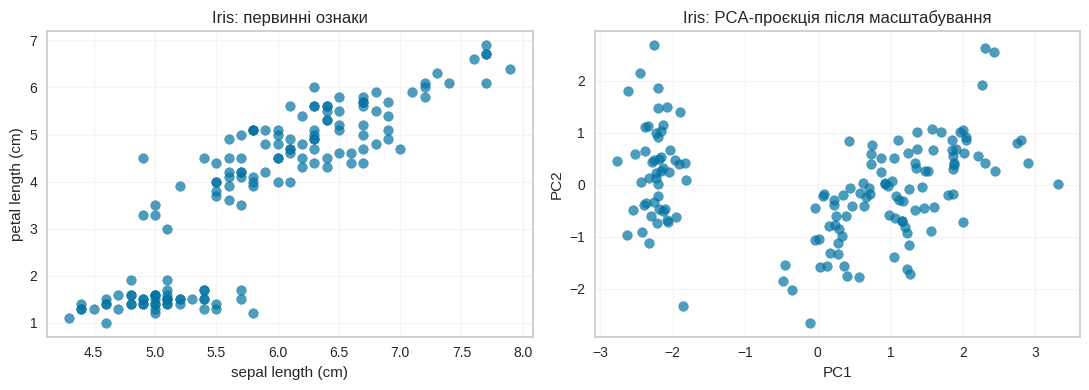

In [63]:
iris = load_iris(as_frame=True)
features_iris = iris.data.copy()
y_iris_reference = iris.target.to_numpy()  # лише для незалежної оцінки згодом

scaler_iris = StandardScaler()
X_iris = scaler_iris.fit_transform(features_iris)
X_iris_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_iris)

print('Розмірність Iris:', X_iris.shape)
print('Середні стандартизованих ознак:', np.round(X_iris.mean(axis=0), 3))
display(features_iris.head())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(features_iris.iloc[:, 0], features_iris.iloc[:, 2], alpha=0.7)
ax[0].set(title='Iris: первинні ознаки', xlabel=features_iris.columns[0],
          ylabel=features_iris.columns[2])
ax[1].scatter(X_iris_2d[:, 0], X_iris_2d[:, 1], alpha=0.7)
ax[1].set(title='Iris: PCA-проєкція після масштабування',
          xlabel='PC1', ylabel='PC2')
plt.tight_layout()
plt.show()

###**Опис ознак набору даних load_iris:**

**sepal length (cm)** - Довжина чашолистка квітки

**sepal width (cm)** - Ширина чашолистка квітки

**petal length (cm)** - Довжина пелюстки квітки

**petal width (cm)** - Ширина пелюстки квітки

Цільова змінна (**target**) містить три класи, які відповідають різним видам ірисів:

0 – Iris setosa (ірис щетинистий);

1 – Iris versicolor (ірис різнокольоровий);

2 – Iris virginica (ірис віргінський).

###**Пояснення:**

За допомогою функції `load_iris(as_frame=True)` завантажено набір даних `Iris`, який містить 150 об'єктів із чотирма числовими ознаками: довжина та ширина чашолистка, довжина та ширина пелюстки.

Створено копію таблиці ознак `features_iris`, а справжні мітки класів збережено у змінній `y_iris_reference` для подальшої незалежної оцінки результатів кластеризації.

За допомогою класу `StandardScaler` та методу `fit_transform()` виконано стандартизацію чотирьох числових ознак, що дозволяє привести їх до однакового масштабу із середнім значенням 0 та стандартним відхиленням 1.

Для зменшення розмірності даних застосовано метод головних компонент `PCA` `(n_components=2)`, який перетворює чотири стандартизовані ознаки на дві головні компоненти для подальшої двовимірної візуалізації.

У результаті виконання коду отримано розмірність набору даних (150, 4), що підтверджує наявність 150 об'єктів із чотирма ознаками.

Середні значення стандартизованих ознак практично дорівнюють нулю ([-0. -0. -0. -0.]), що свідчить про коректне виконання стандартизації.

**Аналіз первинних ознак:**

На першому графіку відображено залежність довжини пелюстки (`petal length`) від довжини чашолистка (`sepal length`). Спостерігається загальна позитивна залежність між цими ознаками: зі збільшенням довжини чашолистка переважно збільшується довжина пелюстки.

Також помітно дві основні області розташування об'єктів: компактну групу з меншою довжиною пелюсток та ширшу групу з більшими значеннями ознак.

**Аналіз PCA-проєкції після стандартизації:**

На другому графіку відображено результати зменшення розмірності даних до двох головних компонент `PC1` та `PC2`.

Чітко простежується одна відокремлена компактна група об'єктів у лівій частині графіка, тоді як решта об'єктів утворюють більш розподілену область із частковим перекриттям.

## 2. K-means: кластеризація навколо центрів

**Відповідність лекції:** §3.

K-means мінімізує суму квадратів відстаней від точок до центрів їхніх кластерів:

$$\operatorname{WCSS}=\sum_{k=1}^{K}\sum_{x_i\in C_k}\|x_i-\mu_k\|^2.$$

**Алгоритм:** ініціалізувати $K$ центрів → призначити кожну точку найближчому центру → перерахувати центри → повторювати до стабілізації. Значення `inertia_` у `sklearn.cluster.KMeans` відповідає WCSS для отриманого розбиття.

Кількість точок у кластерах: {0: 53, 1: 50, 2: 47}
WCSS / inertia_: 139.820
Розмірність центрів: (3, 4)


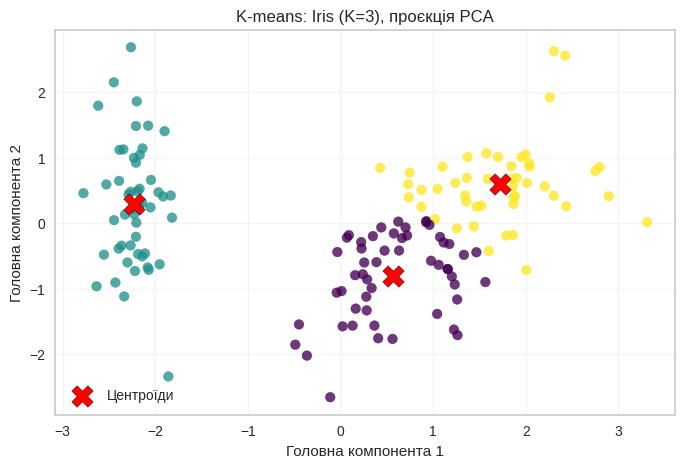

In [64]:
model_iris_km = KMeans(n_clusters=3, init='k-means++',
                        n_init=10, random_state=RANDOM_STATE)
labels_iris_km = model_iris_km.fit_predict(X_iris)

print('Кількість точок у кластерах:',
      pd.Series(labels_iris_km).value_counts().sort_index().to_dict())
print(f'WCSS / inertia_: {model_iris_km.inertia_:.3f}')
print('Розмірність центрів:', model_iris_km.cluster_centers_.shape)

pca_iris = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_iris)
centers_iris_2d = pca_iris.transform(model_iris_km.cluster_centers_)
projected_iris = pca_iris.transform(X_iris)

plt.scatter(projected_iris[:, 0], projected_iris[:, 1],
            c=labels_iris_km, cmap='viridis', alpha=0.78)
plt.scatter(centers_iris_2d[:, 0], centers_iris_2d[:, 1],
            color='red', marker='X', s=240, edgecolor='black', label='Центроїди')
plt.xlabel('Головна компонента 1')
plt.ylabel('Головна компонента 2')
plt.title('K-means: Iris (K=3), проєкція PCA')
plt.legend()
plt.show()

###**Пояснення:**

За допомогою класу `KMeans` із бібліотеки `scikit-learn` виконано кластеризацію набору даних `Iris` на три кластери (`n_clusters=3`) із використанням чотирьох попередньо стандартизованих ознак `X_iris`.

Для ініціалізації центрів кластерів використано метод `init='k-means++'`, який забезпечує вибір початкових центроїдів з урахуванням їх віддаленості.

Параметр `n_init=10` задає кількість незалежних запусків алгоритму, а `random_state=42` забезпечує відтворюваність результатів.

За допомогою методу `fit_predict()` виконано навчання моделі та визначено належність кожного об'єкта до відповідного кластера.

У результаті кластеризації отримано три кластери з такою кількістю об'єктів:

* Кластер 0 – 53 об'єкти;

* Кластер 1 – 50 об'єктів;

* Кластер 2 – 47 об'єктів.

Значення `WCSS` (`inertia_`) = 139.820 характеризує суму квадратів відстаней об'єктів до центроїдів відповідних кластерів.

Менше значення цього показника за однакових умов свідчить про більшу компактність кластерів, однак для оцінювання якості розбиття його необхідно порівнювати з результатами інших значень кількості кластерів.

Розмірність масиву центроїдів (3, 4) підтверджує, що алгоритм визначив три центри кластерів, кожен із яких описується чотирма ознаками.

Для візуалізації результатів використано метод головних компонент `PCA`(`n_components=2`), який дозволяє відобразити чотиривимірні дані на двовимірній площині.

Об'єкти різних кластерів позначено окремими кольорами, а їхні центроїди – червоними хрестиками.

**Аналіз результатів кластеризації:**

На графіку чітко простежується один компактний і добре відокремлений кластер у лівій частині площини, який містить 50 об'єктів.

Два інші кластери розташовані переважно в центральній та правій частинах графіка.

Між ними спостерігається часткове перекриття, що свідчить про складність чіткого розмежування цих груп у двовимірній `PCA`-проєкції.

Червоні хрестики позначають центроїди, навколо яких згруповано об'єкти відповідних кластерів.

Отримані результати демонструють, що алгоритм `K-means` успішно розділив набір даних `Iris` на три групи, однак ступінь їх відокремленості відрізняється.

Один кластер має чітку структуру, тоді як два інші частково перекриваються, що може ускладнювати точне групування схожих об'єктів.

### 2.1. Варіанти K-means

`MiniBatchKMeans` оновлює центри на невеликих пакетах спостережень; `BisectingKMeans` ієрархічно ділить групи на дві частини. Це **не тотожні алгоритми**, тому їхні значення WCSS можуть відрізнятися. Порівняння доцільне на одних і тих самих ознаках.

In [65]:
alternatives = {
    'KMeans': KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE),
    'MiniBatchKMeans': MiniBatchKMeans(n_clusters=3, batch_size=32,
                                     n_init=10, random_state=RANDOM_STATE),
    'BisectingKMeans': BisectingKMeans(n_clusters=3, random_state=RANDOM_STATE)
}
rows = []
for name, estimator in alternatives.items():
    predicted = estimator.fit_predict(X_iris)
    rows.append({'Алгоритм': name, 'WCSS': estimator.inertia_,
                 'Silhouette': silhouette_score(X_iris, predicted),
                 'Розмірів груп': tuple(np.bincount(predicted))})
display(pd.DataFrame(rows).round(3))

,Алгоритм,WCSS,Silhouette,Розмірів груп
0,KMeans,139.820,0.460,"(53, 50, 47)"
1,MiniBatchKMeans,141.080,0.455,"(52, 50, 48)"
2,BisectingKMeans,140.033,0.463,"(50, 56, 44)"


###**Пояснення:**

У цій комірці виконано порівняння трьох алгоритмів кластеризації: `KMeans`, `MiniBatchKMeans` та `BisectingKMeans` на наборі даних `Iris` із використанням чотирьох попередньо стандартизованих ознак `X_iris`.

Для всіх алгоритмів задано однакову кількість кластерів (`n_clusters=3`) та параметр `random_state=42` для забезпечення відтворюваності результатів.

`KMeans` – класичний алгоритм, який ітеративно розподіляє об'єкти між найближчими центроїдами та оновлює їх положення до стабілізації.

`MiniBatchKMeans` – модифікація `K-means`, яка використовує невеликі пакети даних (`batch_size=32`) для оновлення центроїдів, що дозволяє зменшити обчислювальні витрати на великих наборах даних.

`BisectingKMeans` – ієрархічний варіант алгоритму, який послідовно розділяє наявні кластери на дві частини до отримання заданої кількості груп.

За допомогою методу `fit_predict()` виконано навчання кожного алгоритму та визначено належність об'єктів до кластерів.

Для порівняння результатів використано показники `WCSS` (`inertia_`), який характеризує суму квадратів відстаней об'єктів до відповідних центроїдів, та `Silhouette` (`silhouette_score`), який оцінює компактність кластерів і ступінь їх відокремленості.

**Аналіз отриманих результатів:**

`KMeans` отримав найменше значення `WCSS` (139.820) та `Silhouette` 0.460. Розміри сформованих кластерів становлять (53, 50, 47), що свідчить про відносно рівномірний розподіл об'єктів.

`MiniBatchKMeans` показав найбільше значення `WCSS` (141.080) та найменше значення `Silhouette` (0.455). Розміри кластерів (52, 50, 48) також є досить рівномірними.

Незначне погіршення показників порівняно з класичним `KMeans` пояснюється використанням невеликих пакетів даних під час оновлення центроїдів.

`BisectingKMeans` отримав значення `WCSS` 140.033 та найвищий показник `Silhouette (0.463)`.

Розміри кластерів (50, 56, 44) свідчать про дещо менш рівномірний розподіл об'єктів, проте отримані групи мають найкраще співвідношення компактності та відокремленості за метрикою `Silhouette`.

Всі три алгоритми забезпечують близьку якість кластеризації набору даних `Iris`. Класичний `KMeans` забезпечив найменшу суму квадратів відстаней до центроїдів, тоді як `BisectingKMeans` отримав найвище значення `Silhouette`.

`MiniBatchKMeans` показав дещо нижчі значення метрик, проте його перевагою є потенційно менші обчислювальні витрати під час роботи з великими наборами даних.

## 3. Як обрати кількість кластерів K?

**Відповідність лекції:** §8.2–8.4.

Перейдемо до набору **Wine** (13 числових ознак). Заздалегідь задані категорії в наборі даних не використовуємо для вибору $K$.

- **Метод ліктя:** шукаємо уповільнення спадання `inertia_` (WCSS); мінімум WCSS без штрафу не визначає корисне $K$.
- **Silhouette:** більший середній силует означає кращу геометричну компактність і відокремленість.
- **Calinski–Harabasz (CH):** більший — кращий за відповідним критерієм.
- **Davies–Bouldin (DB):** менший — кращий за відповідним критерієм.

Silhouette, CH і DB потребують принаймні двох ненульових кластерів; для `K=1` їх не обчислюємо.

In [66]:
wine = load_wine(as_frame=True)
features_wine = wine.data.copy()
y_wine_reference = wine.target.to_numpy()  # не використовуємо під час навчання
scaler_wine = StandardScaler()
X_wine = scaler_wine.fit_transform(features_wine)

rows_k = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_wine)
    row = {'K': k, 'WCSS': km.inertia_,
           'Silhouette': np.nan, 'CH': np.nan, 'DB': np.nan}
    if k >= 2:
        row['Silhouette'] = silhouette_score(X_wine, labels)
        row['CH'] = calinski_harabasz_score(X_wine, labels)
        row['DB'] = davies_bouldin_score(X_wine, labels)
    rows_k.append(row)

metrics_wine = pd.DataFrame(rows_k).set_index('K')
display(metrics_wine.round(3))

,WCSS,Silhouette,CH,DB
K,,,,
1,2314.000,NaN,NaN,NaN
2,1658.759,0.259,69.523,1.526
3,1277.928,0.285,70.940,1.389
4,1175.428,0.260,56.181,1.797
5,1109.513,0.202,46.952,1.808
6,1046.002,0.237,41.701,1.554
7,981.595,0.204,38.686,1.661
8,935.201,0.157,35.805,1.741
9,889.893,0.150,33.807,1.708


###**Опис ознак набору даних load_wine:**

**alcohol** - Вміст алкоголю у вині

**malic_acid** - Вміст яблучної кислоти

**ash** - Зольність вина

**alcalinity_of_ash** - Лужність золи

**magnesium** - Вміст магнію

**total_phenols** - Загальний вміст фенольних сполук

**flavanoids** - Вміст флавоноїдів

**nonflavanoid_phenols** - Вміст нефлавоноїдних фенолів

**proanthocyanins** - Вміст проантоціанідинів

**color_intensity** - Інтенсивність забарвлення вина

**hue** - Відтінок кольору вина

**od280/od315_of_diluted_wines** - Показник оптичної густини розведеного вина при довжинах хвиль 280 та 315 нм

**proline** - Вміст амінокислоти проліну

Цільова змінна (**target**) містить три класи, які відповідають різним сортам винограду, використаним для виготовлення вина:

0 – Class 0: 59 зразків;

1 – Class 1: 71 зразок;

2 – Class 2: 48 зразків.

###**Пояснення:**

За допомогою функції `load_wine(as_frame=True)` завантажено набір даних `Wine`, який містить 178 об'єктів із 13 числовими ознаками, що характеризують хімічний склад вин.

Створено копію таблиці ознак `features_wine`, а справжні мітки класів збережено у змінній `y_wine_reference` для подальшої незалежної оцінки результатів кластеризації. Під час навчання алгоритму ці мітки не використовуються.

За допомогою класу `StandardScaler` та методу `fit_transform()` виконано стандартизацію 13 числових ознак, щоб привести їх до однакового масштабу та уникнути надмірного впливу ознак із більшими числовими значеннями.

Для визначення оптимальної кількості кластерів використано алгоритм `KMeans`, який послідовно застосовано для значень `K` від 1 до 9. Для кожного значення задано параметри `n_init=10` та `random_state=42`.

За допомогою методу `fit_predict()` виконано кластеризацію даних, після чого обчислено основні метрики оцінювання її якості:

`WCSS` (`inertia_`) – сума квадратів відстаней об'єктів до центроїдів відповідних кластерів. Менше значення свідчить про більшу компактність кластерів.

`Silhouette` (`silhouette_score`) – оцінює компактність і відокремленість кластерів. Чим вище значення, тим кращим є розбиття за цим критерієм.

`Calinski–Harabasz` (`calinski_harabasz_score`) – характеризує співвідношення міжкластерного та внутрішньокластерного розсіювання. Більше значення відповідає кращій якості кластеризації.

`Davies–Bouldin` (`davies_bouldin_score`) – оцінює схожість кластерів з урахуванням їх компактності та відстаней між ними. Менше значення є кращим.

Для `K=1` метрики `Silhouette`, `Calinski–Harabasz` та `Davies–Bouldin` не обчислюються, оскільки вони потребують щонайменше двох кластерів. Тому в таблиці для цього випадку відображено значення `NaN`.

**Аналіз отриманих результатів:**

Показник `WCSS` поступово зменшується зі збільшенням кількості кластерів: від 2314.000 при `K=1` до 889.893 при `K=9`.

Найбільш помітне зниження спостерігається при переході від одного до двох та від двох до трьох кластерів.

Після `K=3` темп зменшення `WCSS` поступово сповільнюється, що вказує на можливе формування «ліктя» в цій області.

`Silhouette` досягає найбільшого значення 0.285 при `K=3`, що свідчить про найкраще співвідношення компактності та відокремленості кластерів серед досліджених варіантів за цією метрикою.

`Calinski–Harabasz` також має максимальне значення 70.940 при `K=3`, що підтверджує перевагу поділу на три кластери за співвідношенням міжкластерного та внутрішньокластерного розсіювання.

`Davies–Bouldin` досягає найменшого значення 1.389 при `K=3`, що свідчить про найкращу якість розбиття серед перевірених значень за цим критерієм.

Найбільш обґрунтованим вибором для набору даних `Wine` є `K=3`, оскільки всі три метрики оцінювання якості кластеризації (`Silhouette`, `Calinski–Harabasz` та `Davies–Bouldin`) показали найкращі значення саме для трьох кластерів.

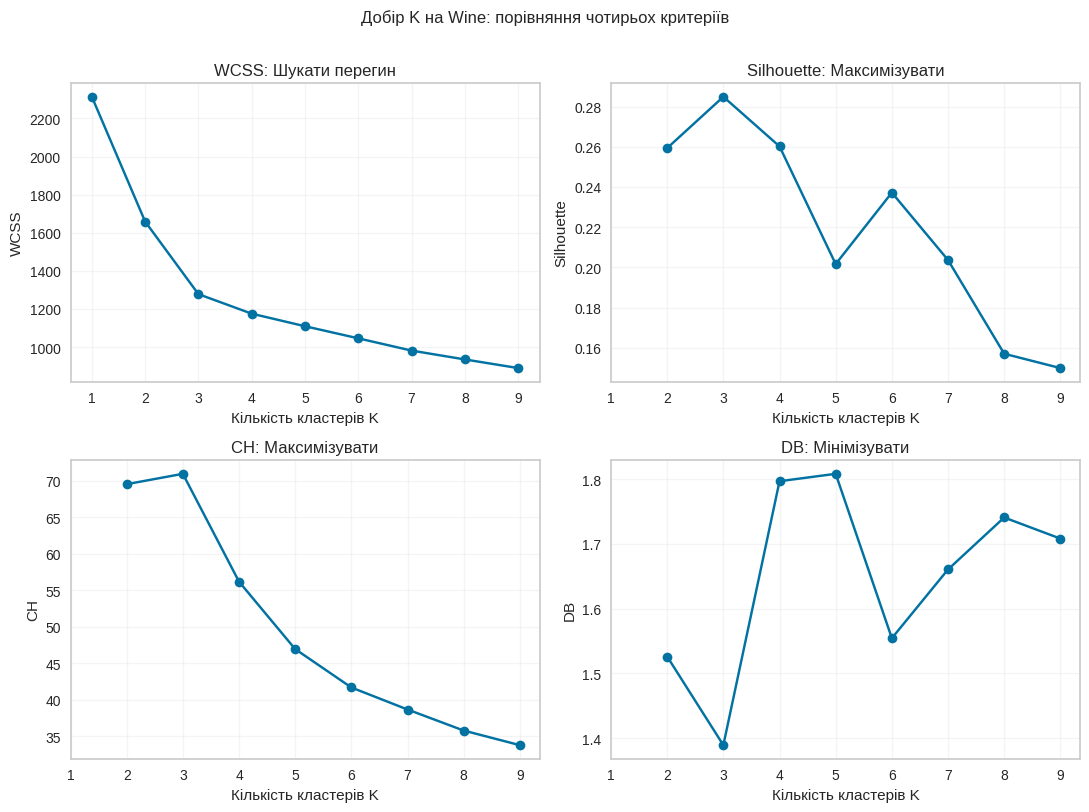

Кандидат за силуетом: 3
Кандидат за CH: 3
Кандидат за DB: 3


In [67]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, metric, prefer in zip(
    axes.flat,
    ['WCSS', 'Silhouette', 'CH', 'DB'],
    ['Шукати перегин', 'Максимізувати', 'Максимізувати', 'Мінімізувати']
):
    ax.plot(metrics_wine.index, metrics_wine[metric], marker='o')
    ax.set(title=f'{metric}: {prefer}', xlabel='Кількість кластерів K',
           ylabel=metric)
    ax.set_xticks(metrics_wine.index)
fig.suptitle('Добір K на Wine: порівняння чотирьох критеріїв', y=1.01)
plt.tight_layout()
plt.show()

print('Кандидат за силуетом:', metrics_wine['Silhouette'].idxmax())
print('Кандидат за CH:', metrics_wine['CH'].idxmax())
print('Кандидат за DB:', metrics_wine['DB'].idxmin())

###**Пояснення:**

За допомогою функції `plt.subplots(2, 2)` побудовано чотири графіки для порівняння критеріїв вибору оптимальної кількості кластерів `K` на наборі даних `Wine`.

Для візуалізації використано попередньо обчислені значення метрик `WCSS`, `Silhouette`, `Calinski–Harabasz` (`CH`) та `Davies–Bouldin` (`DB`) для кількості кластерів від 1 до 9.

За допомогою методу `idxmax()` визначено значення `K`, за яких метрики `Silhouette` та `CH` досягають максимуму, а методом `idxmin()` знайдено мінімальне значення метрики `DB`.

**Аналіз графіка `WCSS` (метод ліктя):**

На графіку спостерігається поступове зменшення значення `WCSS` зі збільшенням кількості кластерів. Найбільш різке зниження відбувається при переході від `K=1` до `K=3`, після чого крива стає більш пологою.

Це свідчить про наявність характерного перегину поблизу `K=3`, після якого збільшення кількості кластерів дає менше покращення компактності груп.

**Аналіз графіка `Silhouette`:**

Найбільше значення коефіцієнта силуету 0.285 спостерігається при `K=3`, що свідчить про найкраще співвідношення компактності та відокремленості кластерів серед досліджених варіантів.

При подальшому збільшенні кількості кластерів значення метрики переважно зменшується, що вказує на погіршення якості розбиття за цим критерієм.

**Аналіз графіка `Calinski–Harabasz` (`CH`):**

Максимальне значення індексу 70.940 досягається при `K=3`. Це свідчить про найкраще співвідношення міжкластерного та внутрішньокластерного розсіювання.

Після `K=3` значення показника послідовно зменшується, що підтверджує доцільність вибору трьох кластерів.

**Аналіз графіка `Davies–Bouldin` (`DB`):**

Мінімальне значення індексу 1.389 отримано при `K=3`, що відповідає найкращій якості кластеризації за цим критерієм.

При інших значеннях `K` показник є вищим, що свідчить про менш сприятливе співвідношення внутрішньокластерного розсіювання та відстаней між кластерами.

### 3.1. Силует для окремих об'єктів

Для точки $i$ величина $a(i)$ — середня відстань до точок її кластера, $b(i)$ — мінімальна середня відстань до іншого кластера. Тоді

$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}}.$$

Близьке до 1 значення відповідає доброму відокремленню; близьке до 0 — прикордонному розташуванню; від'ємне може свідчити про неузгоджену належність. **Середній бал не показує форму розподілу**, тому корисно будувати силуетні профілі.

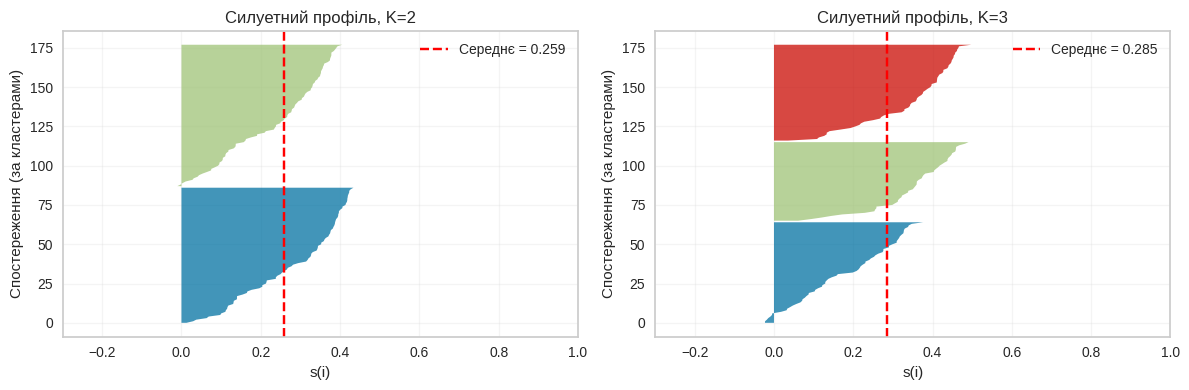

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, k in zip(axes, [2, 3]):
    labels_k = KMeans(n_clusters=k, n_init=10,
                      random_state=RANDOM_STATE).fit_predict(X_wine)
    values = silhouette_samples(X_wine, labels_k)
    left = 0
    for group in np.unique(labels_k):
        group_values = np.sort(values[labels_k == group])
        right = left + len(group_values)
        ax.fill_betweenx(np.arange(left, right), 0, group_values, alpha=0.75)
        left = right
    ax.axvline(float(np.mean(values)), color='red', linestyle='--',
               label=f'Середнє = {np.mean(values):.3f}')
    ax.set(title=f'Силуетний профіль, K={k}', xlabel='s(i)',
           ylabel='Спостереження (за кластерами)', xlim=(-0.3, 1))
    ax.legend()
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою алгоритму `KMeans` виконано кластеризацію набору даних `Wine` для двох варіантів кількості кластерів: `K=2` та `K=3`, використовуючи попередньо стандартизовані ознаки `X_wine`.

Для кожного варіанта за допомогою методу `fit_predict()` визначено належність об'єктів до відповідних кластерів, а функцією `silhouette_samples()` обчислено коефіцієнт силуету для кожного окремого об'єкта.

Отримані значення згруповано за кластерами та відсортовано за зростанням за допомогою `np.sort()`. Для візуалізації використано метод `fill_betweenx()`, який дозволяє побудувати силуетні профілі кожного кластера.

Червона пунктирна лінія, побудована за допомогою `ax.axvline()`, позначає середнє значення коефіцієнта силуету для всіх об'єктів відповідного розбиття.

**Аналіз силуетного профілю для `K=2`:**

На першому графіку відображено два кластери із середнім значенням `Silhouette` 0.259.

Більшість об'єктів мають додатні значення коефіцієнта силуету, проте значна їх частина розташована поблизу нуля, що свідчить про недостатньо чітке розмежування кластерів.

Максимальні значення силуету становлять приблизно 0.4–0.45, а ширина профілів свідчить про нерівномірну відокремленість об'єктів усередині сформованих груп.

**Аналіз силуетного профілю для `K=3`:**

На другому графіку відображено три кластери із середнім значенням `Silhouette` 0.285, що є вищим порівняно з варіантом `K=2`.

Більшість об'єктів мають додатні значення коефіцієнта силуету, а максимальні значення досягають приблизно 0.5, що свідчить про кращу відокремленість частини об'єктів.

Водночас на графіку помітні об'єкти зі значеннями силуету, близькими до нуля, а також окремі від'ємні значення. Це вказує на наявність прикордонних об'єктів, які можуть бути ближчими до іншого кластера, ніж до власного.

**Порівняння отриманих результатів:**

При збільшенні кількості кластерів від `K=2` до `K=3` середнє значення `Silhouette` зростає з 0.259 до 0.285, що свідчить про покращення якості кластеризації за цим критерієм.

Для `K=3` спостерігається більш деталізований розподіл об'єктів на групи, однак окремі кластери залишаються недостатньо чітко відокремленими.

### 3.2. Допоміжна автоматизація: `kneed` і `yellowbrick`

Ці два інструменти **не є вбудованими у `sklearn`**. У Google Colab їх можна встановити, виконавши окрему комірку:

```python
%pip install kneed yellowbrick
```

`KneeLocator` шукає «коліно» кривої WCSS; він може повернути `None`, якщо перегину немає. `KElbowVisualizer` візуалізує оцінки для різних K та повертає `elbow_value_`. Інструменти дають **кандидатне**, а не абсолютне «правильне» число кластерів.

In [69]:
%pip install kneed yellowbrick

###**Пояснення:**

За допомогою команди `%pip install kneed yellowbrick` виконано встановлення додаткових бібліотек `kneed` та `yellowbrick` у середовищі Google Colab, які використовуватимуться для автоматизації вибору оптимальної кількості кластерів.

`Kneed` – бібліотека, яка містить клас `KneeLocator` для автоматичного визначення точки перегину («ліктя») на кривій залежності `WCSS` від кількості кластерів. Це дозволяє знайти значення `K`, після якого подальше збільшення кількості кластерів забезпечує менш суттєве зменшення внутрішньокластерного розсіювання.

`Yellowbrick` – бібліотека для візуального аналізу моделей машинного навчання, яка містить клас `KElbowVisualizer` для побудови графіків оцінювання якості кластеризації та визначення рекомендованої кількості кластерів.

kneed → кандидат K: 3
Yellowbrick → кандидат K: 3


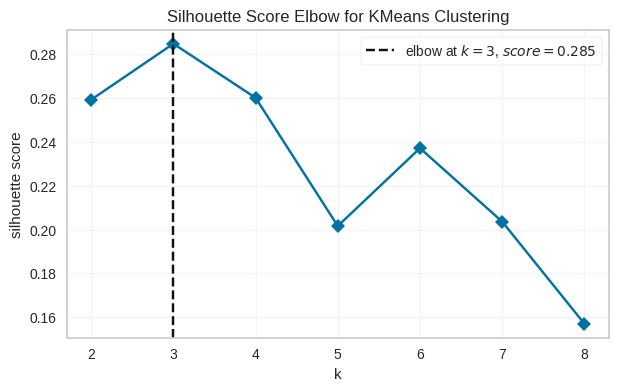

In [70]:
# Комірка безпечна для запуску навіть без необов'язкових пакетів.
try:
    from kneed import KneeLocator
    candidate_knee = KneeLocator(
        metrics_wine.index.to_list(), metrics_wine['WCSS'].to_list(),
        curve='convex', direction='decreasing'
    ).elbow
    print('kneed → кандидат K:', candidate_knee)
    if candidate_knee is None:
        print('Виразного перегину не виявлено; врахуйте інші критерії.')
except ImportError:
    print('Для KneeLocator: виконайте %pip install kneed, потім цю комірку.')

try:
    from yellowbrick.cluster import KElbowVisualizer
    from matplotlib import pyplot as plt
    plt.figure(figsize=(7, 4))
    visualizer = KElbowVisualizer(
        KMeans(n_init=10, random_state=RANDOM_STATE),
        k=(2, 9), metric='silhouette', timings=False
    )
    visualizer.fit(X_wine)
    print('Yellowbrick → кандидат K:', visualizer.elbow_value_)
    visualizer.show()
except ImportError:
    print('Для KElbowVisualizer: виконайте %pip install yellowbrick, потім цю комірку.')

###**Пояснення:**

За допомогою класу `KneeLocator` із бібліотеки `kneed` виконано автоматичний пошук точки перегину («ліктя») на кривій залежності `WCSS` від кількості кластерів для набору даних `Wine`.

Для аналізу використано попередньо обчислені значення `WCSS` із таблиці `metrics_wine`. Параметри `curve='convex'` та `direction='decreasing'` вказують, що досліджувана крива є опуклою та спадною.

У результаті роботи `KneeLocator` визначено кандидата `K=3`, що відповідає точці, після якої зменшення `WCSS` стає менш інтенсивним.

Додатково за допомогою класу `KElbowVisualizer` із бібліотеки `yellowbrick` виконано автоматизований аналіз якості кластеризації алгоритмом `KMeans` для значень `K` від 2 до 8.

Для оцінювання використано метрику `Silhouette` (`metric='silhouette'`), яка характеризує компактність та відокремленість сформованих кластерів. Параметр `timings=False` вимикає відображення часу виконання алгоритму.

Конструкції `try-except` забезпечують коректне виконання комірки навіть за відсутності додаткових бібліотек, виводячи відповідні повідомлення про необхідність їх встановлення.

**Аналіз отриманих результатів:**

За результатами автоматичного аналізу обидва інструменти визначили однакову рекомендовану кількість кластерів:

* Kneed – K=3;

* Yellowbrick – K=3.

На графіку `Silhouette Score Elbow for KMeans Clustering` відображено залежність середнього коефіцієнта силуету від кількості кластерів.

Найбільше значення `Silhouette` 0.285 спостерігається при `K=3`, що свідчить про найкраще співвідношення компактності та відокремленості кластерів серед перевірених варіантів.

Чорна вертикальна пунктирна лінія позначає рекомендовану кількість кластерів `K=3`, автоматично визначену інструментом `KElbowVisualizer`.

При збільшенні кількості кластерів понад три значення `Silhouette` переважно зменшується. Незначне локальне підвищення спостерігається при `K=6`, проте цей результат залишається нижчим за максимальне значення для `K=3`.

## 4. Ієрархічна агломеративна кластеризація

**Відповідність лекції:** §4.

На початку кожна точка є окремим кластером. Надалі найближчі групи послідовно об'єднують. Правило **linkage** визначає міжкластерну відстань: `single`, `complete`, `average` або `ward`. Ward мінімізує приріст внутрішньокластерної суми квадратів (для евклідової геометрії).

**Дендрограма** відображає, на якій «висоті» об'єднувалися групи. Вона допомагає обрати число кластерів за горизонтальним зрізом дерева. Для наочності використаємо перші 45 стандартизованих спостережень Iris, а не всі 150 листків.

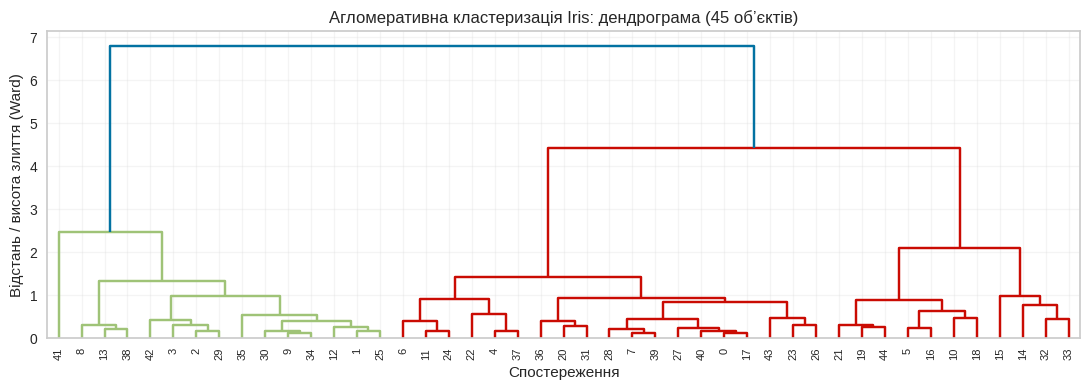

Розміри кластерів Ward: [71 49 30]
ARI(K-means, Ward): 0.626


In [71]:
Z_iris = linkage(X_iris[:45], method='ward')
plt.figure(figsize=(11, 4))
dendrogram(Z_iris, color_threshold=None, leaf_rotation=90)
plt.title('Агломеративна кластеризація Iris: дендрограма (45 об’єктів)')
plt.xlabel('Спостереження')
plt.ylabel('Відстань / висота злиття (Ward)')
plt.tight_layout()
plt.show()

agg_iris = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_iris_ward = agg_iris.fit_predict(X_iris)
print('Розміри кластерів Ward:', np.bincount(labels_iris_ward))
print('ARI(K-means, Ward):',
      round(adjusted_rand_score(labels_iris_km, labels_iris_ward), 3))

###**Пояснення:**

За допомогою функції `linkage()` із бібліотеки `SciPy` виконано ієрархічну агломеративну кластеризацію перших 45 стандартизованих об'єктів набору даних `Iris` із використанням методу Варда (`method='ward'`).

Метод `Ward` передбачає послідовне об'єднання кластерів таким чином, щоб приріст внутрішньокластерної суми квадратів відхилень був мінімальним.

За допомогою функції `dendrogram()` побудовано дендрограму, яка відображає послідовність об'єднання об'єктів у кластери та висоту, на якій відбувається їх злиття. Параметр `leaf_rotation=90` використано для вертикального розташування підписів спостережень.

Додатково за допомогою класу `AgglomerativeClustering` виконано кластеризацію всіх 150 об'єктів набору `Iris` на три кластери (`n_clusters=3`) із використанням методу `linkage='ward'`.

За допомогою методу `fit_predict()` визначено належність кожного об'єкта до відповідного кластера, а функцією `np.bincount()` обчислено кількість об'єктів у сформованих групах.

Для порівняння результатів агломеративної кластеризації з алгоритмом `K-means` використано метрику `Adjusted Rand Index` (`adjusted_rand_score`), яка оцінює ступінь узгодженості двох кластерних розбиттів з урахуванням випадкових збігів.

**Аналіз дендрограми:**

На дендрограмі відображено послідовність об'єднання 45 об'єктів набору `Iris` у кластери. По горизонтальній осі розташовано індекси спостережень, а по вертикальній – відстань або висоту злиття кластерів за методом `Ward`.

На нижніх рівнях дендрограми відбувається об'єднання найбільш схожих об'єктів, тоді як на вищих рівнях поступово об'єднуються більші та менш схожі групи.

Найбільше злиття відбувається на висоті приблизно 6.7, коли дві великі групи об'єднуються в один кластер. Попереднє значне злиття спостерігається на висоті приблизно 4.5.

Горизонтальний зріз дендрограми між цими рівнями дозволяє виділити дві основні групи об'єктів. При нижчому рівні зрізу можна отримати більшу кількість кластерів.

**Аналіз результатів кластеризації:**

У результаті застосування алгоритму `AgglomerativeClustering` до всіх 150 об'єктів отримано три кластери з такими розмірами:

* Кластер 0 – 71 об'єкт;

* Кластер 1 – 49 об'єктів;

* Кластер 2 – 30 об'єктів.

Отримані розміри кластерів свідчать про нерівномірний розподіл об'єктів між групами, що відрізняється від результатів алгоритму `K-means`, для якого кількість об'єктів у кластерах становила 53, 50 та 47.

Значення `ARI = 0.626` свідчить про помітну, але неповну узгодженість результатів кластеризації `K-means` та `Ward`. Це означає, що обидва алгоритми формують частково подібні групи, проте для деяких об'єктів визначають різну кластерну належність.

### 4.1. Що робити без наперед заданого K?

`AgglomerativeClustering` підтримує аргумент `distance_threshold`: якщо його задано, `n_clusters=None`. Тоді модель утворює число груп відповідно до порога, а не до фіксованого K.

In [72]:
threshold = float(np.percentile(Z_iris[:, 2], 85))
agg_threshold = AgglomerativeClustering(
    n_clusters=None, distance_threshold=threshold, linkage='ward'
)
labels_threshold = agg_threshold.fit_predict(X_iris[:45])
print('Висота зрізу:', round(threshold, 3))
print('Кількість знайдених груп:', np.unique(labels_threshold).size)

Висота зрізу: 0.981
Кількість знайдених груп: 8


###**Пояснення:**

За допомогою класу `AgglomerativeClustering` із бібліотеки `scikit-learn` виконано ієрархічну агломеративну кластеризацію без попереднього задання кількості кластерів `K` на основі перших 45 стандартизованих об'єктів набору даних `Iris`.

Для визначення порога об'єднання кластерів використано функцію `np.percentile()`, яка обчислює 85-й процентиль висот злиття з матриці ієрархічної кластеризації `Z_iris`. Отримане значення використано як поріг відстані `distance_threshold`.

Під час створення моделі задано параметри `n_clusters=None`, `distance_threshold=threshold` та `linkage='ward'`. Це дозволяє алгоритму визначати кількість кластерів автоматично відповідно до встановленого порога, а не заздалегідь заданого значення `K`.

За допомогою методу `fit_predict()` виконано кластеризацію об'єктів та визначено їх належність до сформованих груп. Функція `np.unique()` використана для підрахунку кількості отриманих кластерів.

У результаті отримано висоту зрізу 0.981, яка визначає максимальний рівень злиття кластерів відповідно до встановленого порога.

За цього значення алгоритм автоматично сформував 8 кластерів із 45 об'єктів набору `Iris`.

## 5. Алгоритми щільнісної кластеризації

**Відповідність лекції:** §5.

`DBSCAN` використовує:
- `eps`: радіус околу точки;
- `min_samples`: мінімальна кількість об'єктів у ε-околі (включно з самою точкою) для базової точки.

Кластери утворюються із щільнісно зв'язаних точок. Мітка **−1** означає шум. На відміну від K-means, число кластерів не потрібно задавати заздалегідь, але воно залежить від параметрів щільності.

Використаємо **make_moons**: дві зігнуті групи, на яких сферичне припущення K-means може бути невдалим.

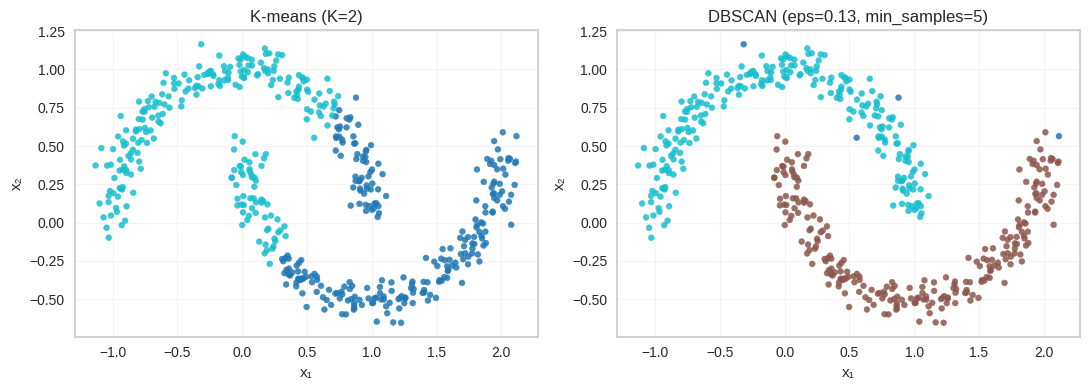

DBSCAN: кластерів 2, шумових точок 4 (0.8%)


In [73]:
X_moons, _ = make_moons(n_samples=500, noise=0.07,
                         random_state=RANDOM_STATE)
labels_moons_km = KMeans(n_clusters=2, n_init=10,
                         random_state=RANDOM_STATE).fit_predict(X_moons)
model_moons_dbscan = DBSCAN(eps=0.13, min_samples=5)
labels_moons_dbscan = model_moons_dbscan.fit_predict(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, labs, title in zip(
    axes, [labels_moons_km, labels_moons_dbscan],
    ['K-means (K=2)', 'DBSCAN (eps=0.13, min_samples=5)']
):
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=labs,
               cmap='tab10', s=18, alpha=0.85)
    ax.set(title=title, xlabel='x₁', ylabel='x₂')
plt.tight_layout()
plt.show()

n_clusters = len(set(labels_moons_dbscan) - {-1})
noise_count = int((labels_moons_dbscan == -1).sum())
print(f'DBSCAN: кластерів {n_clusters}, шумових точок {noise_count} '
      f'({noise_count / len(X_moons):.1%})')

###**Пояснення:**

За допомогою функції `make_moons()` із бібліотеки `scikit-learn` згенеровано штучний набір даних із 500 об'єктів, які утворюють дві вигнуті групи у формі півмісяців. Параметр `noise=0.07` задає рівень випадкового шуму, а `random_state=42` забезпечує відтворюваність результатів.

Для порівняння використано два алгоритми кластеризації: `KMeans` та `DBSCAN`, які застосовано до однакового набору даних `X_moons`.

За допомогою алгоритму `KMeans` виконано розподіл об'єктів на два кластери (`n_clusters=2`). Для стабільності результатів використано параметри `n_init=10` та `random_state=42`.

Алгоритм `DBSCAN` застосовано з параметрами `eps=0.13` та `min_samples=5`. Параметр `eps` визначає радіус околу точки, а `min_samples` задає мінімальну кількість об'єктів у цьому околі для визначення базової точки.

За допомогою методу `fit_predict()` виконано кластеризацію обома алгоритмами, після чого побудовано два графіки для порівняння отриманих результатів.

**Аналіз результатів `K-means`:**

На першому графіку відображено результати кластеризації алгоритмом `KMeans` (`K=2`).

Алгоритм розділив об'єкти на дві групи, проте межі кластерів не відповідають природній вигнутій формі півмісяців. Частина точок верхнього та нижнього півмісяців потрапила до одного кластера, хоча вони належать до різних геометричних структур.

Це пояснюється тим, що `KMeans` групує об'єкти навколо центроїдів, тому може некоректно розділяти дані зі складною нелінійною формою кластерів.

**Аналіз результатів `DBSCAN`:**

На другому графіку відображено результати щільнісної кластеризації алгоритмом `DBSCAN`.

На відміну від `KMeans`, алгоритм правильно виділив дві вигнуті групи, які відповідають природній структурі згенерованих даних.

У результаті виконання коду отримано 2 кластери та 4 шумові точки (0.8%).

Шумові точки позначаються міткою -1 та відповідають об'єктам, які не були віднесені до жодного кластера через недостатню щільність їхнього оточення.

Невелика частка шумових точок свідчить про те, що більшість об'єктів успішно об'єднано у відповідні групи, а окремі спостереження визначено як шум.

**Порівняння отриманих результатів:**

Алгоритм `KMeans` сформував два кластери, проте не зміг правильно відтворити їхню нелінійну геометричну форму.

Натомість `DBSCAN` успішно виявив дві групи у формі півмісяців та додатково визначив 4 шумові точки, не зараховуючи їх до основних кластерів.

### 5.1. Як обрати `eps`: k-distance графік

Для кожної точки знаходимо відстань до `min_samples`-го найближчого сусіда. Після сортування відстаней шукаємо перехід до області різкого зростання. Це **евристика**, а не гарантований критерій оптимальності. Параметр `eps` має ті самі одиниці, що й відстані у просторі ознак.

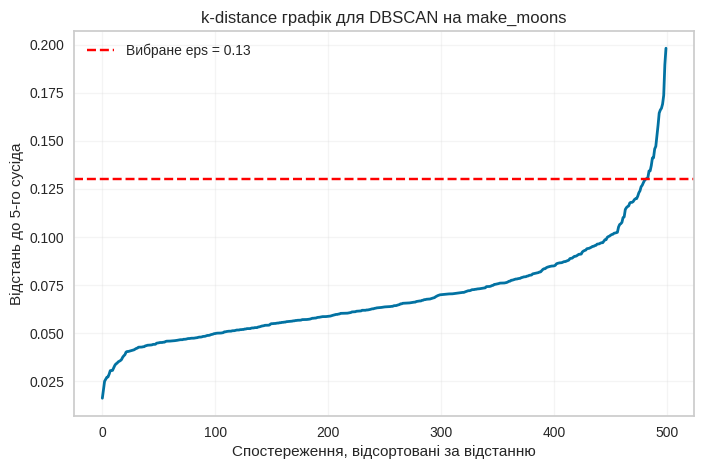

In [74]:
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples).fit(X_moons)
distances, _ = neighbors.kneighbors(X_moons)
k_distances = np.sort(distances[:, -1])

plt.plot(k_distances, lw=2)
plt.axhline(0.13, linestyle='--', color='red', label='Вибране eps = 0.13')
plt.title('k-distance графік для DBSCAN на make_moons')
plt.xlabel('Спостереження, відсортовані за відстанню')
plt.ylabel(f'Відстань до {min_samples}-го сусіда')
plt.legend()
plt.show()

###**Пояснення:**

За допомогою класу `NearestNeighbors` із бібліотеки `scikit-learn` виконано пошук найближчих сусідів для кожного об'єкта набору даних `X_moons`, що містить 500 точок, розташованих у формі двох півмісяців.

Для пошуку задано параметр `n_neighbors=5`, який відповідає значенню `min_samples=5`, використаному раніше в алгоритмі `DBSCAN`.

За допомогою методу `fit()` побудовано модель пошуку найближчих сусідів, а методом `kneighbors()` обчислено відстані від кожного об'єкта до його п'ятого найближчого сусіда (включно із самим об'єктом).

Отримані відстані відсортовано за зростанням за допомогою `np.sort()`, після чого побудовано `k-distance` графік, який використовується для обґрунтування вибору параметра `eps` в алгоритмі `DBSCAN`.

Червона горизонтальна пунктирна лінія, побудована за допомогою `plt.axhline()`, позначає раніше вибране значення `eps = 0.13`.

**Аналіз отриманого графіка:**

На графіку відображено залежність відстані до п'ятого найближчого сусіда від порядкового номера спостереження після сортування за відстанню.

На початковій та середній ділянках кривої спостерігається плавне зростання відстаней приблизно від 0.02 до 0.10, що свідчить про відносно високу щільність розташування більшості об'єктів.

Ближче до кінця графіка, приблизно після 450-го спостереження, крива починає зростати інтенсивніше. Це вказує на перехід до області меншої щільності, де відстані між сусідніми об'єктами стають більшими.

Найбільш різке зростання спостерігається наприкінці кривої, де відстані досягають приблизно 0.20. Такі значення характерні для більш ізольованих об'єктів, які потенційно можуть бути визначені алгоритмом `DBSCAN` як шумові.

Вибране значення `eps = 0.13` розташоване поблизу області переходу від плавного до різкого зростання кривої, що підтверджує доцільність його використання для цього набору даних.

При меншому значенні `eps` алгоритм може визначати більшу кількість об'єктів як шум або розділяти щільні групи на дрібніші кластери. При більшому значенні `eps` зростає ймовірність об'єднання сусідніх груп в один кластер.

### 5.2. OPTICS та HDBSCAN

`OPTICS` аналізує щільнісну структуру на різних масштабах околу. `HDBSCAN` будує ієрархію щільнісних груп і виділяє стійкі кластери. Як і DBSCAN, ці алгоритми можуть залишати точки шумом. Приклад використовує **вбудований** `sklearn.cluster.HDBSCAN` (у сучасних версіях `scikit-learn`).

In [75]:
density_algorithms = {
    'DBSCAN': DBSCAN(eps=0.13, min_samples=5),
    'OPTICS': OPTICS(min_samples=8, min_cluster_size=20,
                     cluster_method='xi', xi=0.05),
    'HDBSCAN': HDBSCAN(min_cluster_size=20, min_samples=8, copy=True)
}
summary_density = []
for name, estimator in density_algorithms.items():
    labels = estimator.fit_predict(X_moons)
    summary_density.append({
        'Алгоритм': name,
        'Кластерів без шуму': len(set(labels) - {-1}),
        'Частка шуму': np.mean(labels == -1)
    })
display(pd.DataFrame(summary_density).round(3))

,Алгоритм,Кластерів без шуму,Частка шуму
0,DBSCAN,2,0.008
1,OPTICS,10,0.324
2,HDBSCAN,2,0.000


###**Пояснення:**

Виконано порівняння трьох алгоритмів щільнісної кластеризації: `DBSCAN`, `OPTICS` та `HDBSCAN` на штучному наборі даних `X_moons`, який містить 500 об'єктів, розташованих у формі двох півмісяців.

Для кожного алгоритму задано відповідні параметри кластеризації:

`DBSCAN` – використано параметри `eps=0.13` та `min_samples=5`, які визначають радіус околу точки та мінімальну кількість сусідніх об'єктів для формування щільної області.

`OPTICS` – використано параметри `min_samples=8`, `min_cluster_size=20`, `cluster_method='xi'` та `xi=0.05`. Алгоритм аналізує структуру щільності даних на різних масштабах, а параметр `xi` визначає поріг відносної зміни досяжності для виділення кластерів.

`HDBSCAN` – використано параметри `min_cluster_size=20` та `min_samples=8`. Алгоритм формує ієрархію щільнісних груп та виділяє стійкі кластери, враховуючи можливі відмінності у щільності розташування об'єктів.

За допомогою методу `fit_predict()` виконано кластеризацію кожним алгоритмом та визначено належність об'єктів до відповідних груп.

Для порівняння результатів обчислено кількість кластерів без урахування шуму та частку шумових точок, які алгоритми позначили міткою -1.

**Аналіз отриманих результатів:**

`DBSCAN` сформував 2 кластери із часткою шумових точок 0.008 (0.8%), що відповідає 4 об'єктам із 500. Отриманий результат свідчить про успішне виділення двох основних груп із незначною кількістю точок, не віднесених до жодного кластера.

`OPTICS` визначив 10 кластерів із часткою шумових точок 0.324 (32.4%), що відповідає 162 об'єктам. Такий результат свідчить про значно детальніше розбиття даних на невеликі групи та віднесення великої кількості об'єктів до шуму. Це може бути пов'язано з особливостями аналізу щільності та вибраними параметрами `xi` і `min_cluster_size`.

`HDBSCAN` сформував 2 кластери із часткою шумових точок 0.000 (0%). Отже, усі 500 об'єктів було віднесено до одного з двох кластерів без виділення шумових точок.

**Порівняння отриманих результатів:**

Алгоритми `DBSCAN` та `HDBSCAN` визначили однакову кількість кластерів – 2, що відповідає очікуваній структурі набору даних `make_moons`. Водночас `DBSCAN` виділив 4 шумові точки, тоді як `HDBSCAN` відніс усі об'єкти до сформованих груп.

Натомість `OPTICS` за заданих параметрів сформував 10 кластерів та визначив значну частину об'єктів як шум, що свідчить про надмірну деталізацію розбиття для цього прикладу.

### 5.3. Коректне оцінювання результатів з шумом

Не слід механічно вважати `-1` «звичайним кластером». Наведений нижче силует обчислюємо **лише для точок, віднесених до кластерів**, і обов'язково вказуємо частку відкинутих спостережень. Якщо після відкидання шуму лишається менше двох груп, силует не визначений.

In [76]:
labels = labels_moons_dbscan
is_clustered = labels != -1
n_groups = np.unique(labels[is_clustered]).size
print(f'Частка шуму: {(~is_clustered).mean():.3f}')
if 2 <= n_groups < is_clustered.sum():
    score = silhouette_score(X_moons[is_clustered], labels[is_clustered])
    print(f'Силует тільки для не-шумових точок: {score:.3f}')
else:
    print('Силует не визначений: потрібні принаймні 2 коректні кластери.')

Частка шуму: 0.008
Силует тільки для не-шумових точок: 0.332


###**Пояснення:**

За допомогою результатів попередньої кластеризації `labels_moons_dbscan` виконано оцінювання якості роботи алгоритму `DBSCAN` на наборі даних `X_moons` з урахуванням шумових точок.

За допомогою умови `labels != -1` створено логічну маску `is_clustered`, яка дозволяє відокремити об'єкти, віднесені до кластерів, від шумових спостережень із міткою -1.

Функцію `np.unique()` використано для визначення кількості сформованих кластерів без урахування шуму, а вираз (`~is_clustered`).`mean()` – для обчислення частки шумових точок у наборі даних.

Для оцінювання якості кластеризації застосовано метрику `Silhouette` (`silhouette_score`), яка обчислюється лише для об'єктів, віднесених до кластерів. Перед обчисленням перевіряється наявність щонайменше двох кластерів та достатньої кількості об'єктів.

**Аналіз отриманих результатів:**

У результаті отримано частку шуму 0.008 (0.8%), що відповідає 4 об'єктам із 500, які алгоритм `DBSCAN` не відніс до жодного кластера.

Значення `Silhouette` = 0.332 обчислено лише для 496 об'єктів, які належать до двох сформованих кластерів.

Отримане додатне значення коефіцієнта силуету свідчить про певну компактність та відокремленість кластерів, проте відносно невисокий показник вказує на те, що за цією метрикою розбиття не є ідеальним.

Водночас набір даних `make_moons` має складну нелінійну структуру у формі двох півмісяців, тому метрика `Silhouette`, яка базується на відстанях між об'єктами, не завжди повністю відображає якість кластеризації таких груп.

## 6. Інші алгоритми кластеризації

**Відповідність лекції:** §6.

`MeanShift` зсуває центри до локальних максимумів оціненої щільності, тому не вимагає попереднього K. `AffinityPropagation` передає «повідомлення» між об'єктами та визначає представників груп. `Birch` створює компактні підструктури, а `SpectralClustering` використовує спектральні властивості графа подібності.

**Пам'ятайте:** автоматично визначене число груп не означає автоматичну гарантію їхньої предметної якості.

MeanShift, bandwidth: 1.242
MeanShift, кількість кластерів: 3
AffinityPropagation, кількість кластерів на підвибірці: 3
Кількість представників: 3


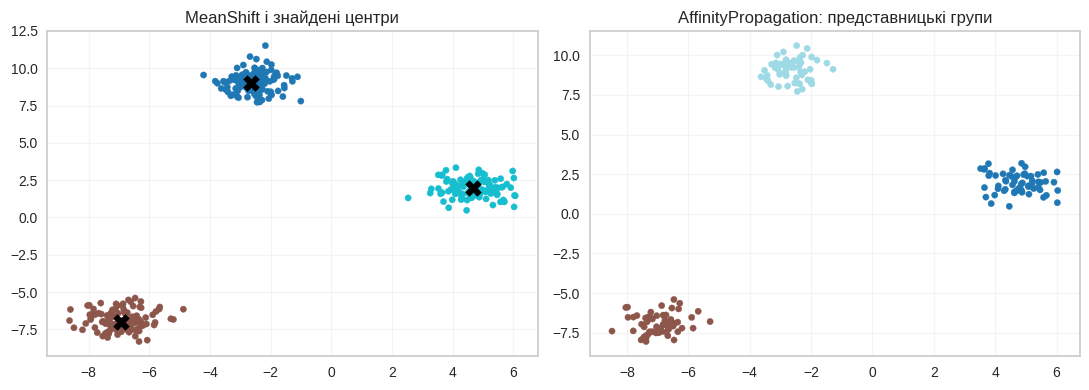

In [77]:
X_blobs, _ = make_blobs(n_samples=350, centers=3,
                        cluster_std=0.65, random_state=RANDOM_STATE)
bandwidth = estimate_bandwidth(X_blobs, quantile=0.20,
                               n_samples=250, random_state=RANDOM_STATE)
ms = MeanShift(bandwidth=bandwidth, bin_seeding=True)
labels_ms = ms.fit_predict(X_blobs)
print('MeanShift, bandwidth:', round(bandwidth, 3))
print('MeanShift, кількість кластерів:', len(set(labels_ms)))

ap = AffinityPropagation(random_state=RANDOM_STATE, damping=0.7)
labels_ap = ap.fit_predict(X_blobs[:180])
print('AffinityPropagation, кількість кластерів на підвибірці:',
      len(set(labels_ap)))
print('Кількість представників:', len(ap.cluster_centers_indices_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels_ms,
              cmap='tab10', s=20)
ax[0].scatter(ms.cluster_centers_[:, 0], ms.cluster_centers_[:, 1],
              color='black', marker='X', s=130)
ax[0].set_title('MeanShift і знайдені центри')
ax[1].scatter(X_blobs[:180, 0], X_blobs[:180, 1], c=labels_ap,
              cmap='tab20', s=20)
ax[1].set_title('AffinityPropagation: представницькі групи')
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою функції `make_blobs()` із бібліотеки `scikit-learn` згенеровано штучний набір даних `X_blobs`, який містить 350 об'єктів, розподілених навколо трьох центрів (`centers=3`). Параметр `cluster_std=0.65` визначає стандартне відхилення точок від центрів груп, а `random_state=42` забезпечує відтворюваність результатів.

Для дослідження використано два алгоритми кластеризації: `MeanShift` та `AffinityPropagation`, які дозволяють визначати кількість кластерів без попереднього задання параметра `K`.

За допомогою функції `estimate_bandwidth()` обчислено параметр `bandwidth`, який визначає ширину області пошуку локальних максимумів щільності для алгоритму `MeanShift`. Для оцінювання використано параметри `quantile=0.20` та `n_samples=250`.

Алгоритм `MeanShift` застосовано з отриманим значенням `bandwidth` та параметром `bin_seeding=True`, який дозволяє використовувати початкові точки, сформовані на основі групування даних у комірки сітки, для зменшення обчислювальних витрат.

Алгоритм `AffinityPropagation` застосовано з параметрами `damping=0.7` та `random_state=42`. Параметр `damping` забезпечує стабільність оновлення повідомлень між об'єктами під час визначення представників кластерів.

Для зменшення обчислювальних витрат алгоритм `AffinityPropagation` застосовано лише до перших 180 об'єктів набору даних `X_blobs`, тоді як `MeanShift` використано для всіх 350 об'єктів.

За допомогою методу `fit_predict()` виконано кластеризацію даних, після чого визначено кількість сформованих кластерів. Для `MeanShift` додатково отримано координати центрів кластерів, а для `AffinityPropagation` – кількість об'єктів-представників.

**Аналіз отриманих результатів:**

У результаті виконання алгоритму `MeanShift` отримано значення `bandwidth = 1.242`, яке використано для визначення областей підвищеної щільності даних.

Алгоритм автоматично сформував 3 кластери, що відповідає початковій структурі згенерованого набору даних.

Алгоритм `AffinityPropagation` також визначив 3 кластери та виділив 3 об'єкти-представники, навколо яких сформовано відповідні групи.

**Аналіз графіка `MeanShift`:**

На першому графіку відображено результати кластеризації всіх 350 об'єктів алгоритмом `MeanShift`.

Чітко простежуються три компактні та добре відокремлені групи точок, розташовані в різних областях двовимірного простору ознак.

Кольорами позначено належність об'єктів до відповідних кластерів, а чорними хрестиками – знайдені центри кластерів.

Центри розташовані поблизу областей найбільшої щільності кожної групи, що свідчить про коректне визначення структури даних алгоритмом `MeanShift`.

**Аналіз графіка `AffinityPropagation`:**

На другому графіку відображено результати кластеризації перших 180 об'єктів алгоритмом `AffinityPropagation`.

Алгоритм також виділив три чітко відокремлені групи, які відповідають природному розташуванню точок у наборі даних.

Кожен кластер позначено окремим кольором. Для трьох сформованих груп визначено по одному об'єкту-представнику, які використовуються алгоритмом для організації кластерів.

На відміну від `MeanShift`, алгоритм `AffinityPropagation` визначає представників серед наявних об'єктів, а не обчислює центри як локальні максимуми оціненої щільності.

**Порівняння отриманих результатів:**

Обидва алгоритми `MeanShift` та `AffinityPropagation` автоматично визначили по 3 кластери, що відповідає початковій кількості груп у згенерованому наборі даних `make_blobs`.

Водночас алгоритми використовують різні принципи формування кластерів: `MeanShift` знаходить центри областей підвищеної щільності, тоді як `AffinityPropagation` визначає об'єкти-представники на основі обміну повідомленнями між точками.

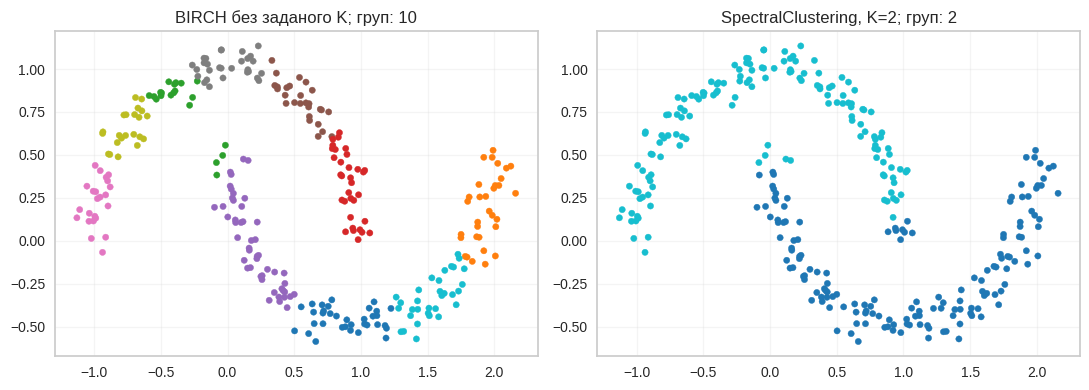

In [78]:
birch = Birch(threshold=0.3, n_clusters=None)
spectral = SpectralClustering(n_clusters=2, affinity='rbf',
                              gamma=10.0, random_state=RANDOM_STATE)
X_moons_small, _ = make_moons(n_samples=300, noise=0.06,
                              random_state=RANDOM_STATE)
labels_birch = birch.fit_predict(X_moons_small)
labels_spectral = spectral.fit_predict(X_moons_small)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for axes, labels, name in zip(ax, [labels_birch, labels_spectral],
                              ['BIRCH без заданого K', 'SpectralClustering, K=2']):
    axes.scatter(X_moons_small[:, 0], X_moons_small[:, 1],
                 c=labels, cmap='tab10', s=20)
    axes.set_title(f'{name}; груп: {len(set(labels))}')
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою функції `make_moons()` із бібліотеки `scikit-learn` згенеровано штучний набір даних `X_moons_small`, який містить 300 об'єктів, розташованих у формі двох півмісяців. Параметр `noise=0.06` задає рівень випадкового шуму, а `random_state=42` забезпечує відтворюваність результатів.

Для дослідження використано два алгоритми кластеризації: `BIRCH` та `SpectralClustering`, які застосовано до однакового набору даних.

Алгоритм `BIRCH` застосовано з параметрами `threshold=0.3` та `n_clusters=None`. Параметр `threshold` визначає допустимий радіус підкластерів у структурі `CF`-дерева, а `n_clusters=None` означає, що додаткове глобальне об'єднання підкластерів до наперед заданої кількості груп не виконується.

Алгоритм `SpectralClustering` застосовано з параметрами `n_clusters=2`, `affinity='rbf'` та `gamma=10.0`. Параметр `affinity='rbf'` задає використання радіальної базисної функції для обчислення подібності між об'єктами, а `gamma` визначає чутливість цієї функції до відстаней між точками.

За допомогою методу `fit_predict()` виконано кластеризацію даних обома алгоритмами та визначено належність кожного об'єкта до відповідної групи.

Для візуалізації результатів побудовано два графіки розсіювання за допомогою `plt.subplots()` та `scatter()`, на яких об'єкти різних кластерів позначено окремими кольорами.

**Аналіз графіка `BIRCH`:**

На першому графіку відображено результати кластеризації алгоритмом `BIRCH` без попереднього задання кількості кластерів `K`.

У результаті виконання алгоритму сформовано 10 кластерів, які охоплюють окремі ділянки двох вигнутих груп.

Спостерігається, що кожен півмісяць поділено на декілька менших кластерів, хоча початкова структура набору даних містить лише дві основні групи.

Це свідчить про надмірну деталізацію кластеризації, оскільки алгоритм формує компактні підкластери відповідно до встановленого порога `threshold=0.3`, не об'єднуючи їх у дві загальні групи.

**Аналіз графіка `SpectralClustering`:**

На другому графіку відображено результати спектральної кластеризації алгоритмом `SpectralClustering` (`K=2`).

Алгоритм сформував 2 кластери, які відповідають природній геометричній структурі набору даних `make_moons`.

Чітко простежується розділення об'єктів на два вигнуті півмісяці, кожен із яких позначено окремим кольором.

На відміну від `BIRCH`, алгоритм `SpectralClustering` успішно врахував нелінійну форму груп, використовуючи спектральні властивості матриці подібності між об'єктами.

**Порівняння отриманих результатів:**

Алгоритм `BIRCH` сформував 10 компактних підкластерів, що дозволило детально розділити дані на локальні групи, проте не забезпечило відтворення двох основних геометричних структур.

Натомість `SpectralClustering` правильно виділив дві групи у формі півмісяців, що відповідає початковій структурі згенерованих даних.

## 7. Імовірнісна кластеризація: Gaussian Mixture Models

**Відповідність лекції:** §7.

На відміну від «жорстких» міток K-means, **GMM** оцінює умовні ймовірності належності точки до кожного гауссового компонента: `predict_proba(X)`.

$$p(x)=\sum_{k=1}^{K}\pi_k\,\mathcal N(x\mid\mu_k,\Sigma_k),\qquad\sum_k\pi_k=1.$$

У GMM кількість компонентів — не обов'язково кількість предметно змістовних груп. Навчання зазвичай ґрунтується на EM-подібному алгоритмі.

Ваги компонент: [0.25 0.25 0.25 0.25]
Форма матриці ймовірностей: (500, 4)
Ймовірності належності першого об’єкта: [0. 1. 0. 0.] | сума = 1.0


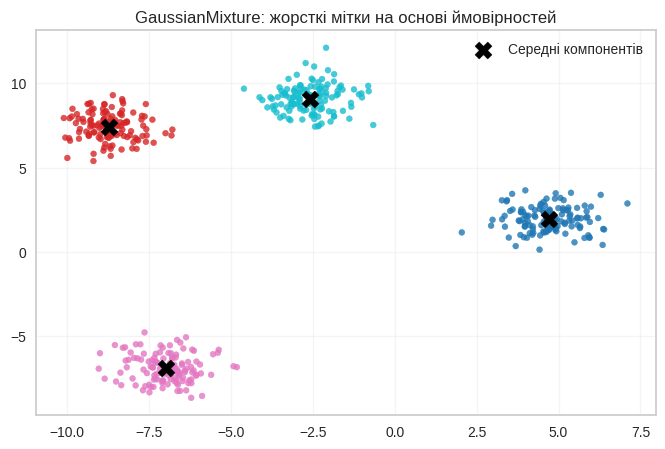

In [79]:
X_gmm, _ = make_blobs(n_samples=500, centers=4,
                      cluster_std=0.8, random_state=RANDOM_STATE)
gmm = GaussianMixture(n_components=4, covariance_type='full',
                      n_init=3, random_state=RANDOM_STATE)
gmm.fit(X_gmm)
labels_gmm = gmm.predict(X_gmm)
proba_gmm = gmm.predict_proba(X_gmm)

print('Ваги компонент:', np.round(gmm.weights_, 3))
print('Форма матриці ймовірностей:', proba_gmm.shape)
print('Ймовірності належності першого об’єкта:',
      np.round(proba_gmm[0], 3), '| сума =', round(proba_gmm[0].sum(), 4))

plt.scatter(X_gmm[:, 0], X_gmm[:, 1], c=labels_gmm,
            cmap='tab10', s=18, alpha=0.8)
plt.scatter(gmm.means_[:, 0], gmm.means_[:, 1],
            marker='X', color='black', s=150, label='Середні компонентів')
plt.title('GaussianMixture: жорсткі мітки на основі ймовірностей')
plt.legend()
plt.show()

###**Пояснення:**

За допомогою функції `make_blobs()` із бібліотеки `scikit-learn` згенеровано штучний набір даних `X_gmm`, який містить 500 об'єктів, розподілених навколо чотирьох центрів (`centers=4`). Параметр `cluster_std=0.8` визначає стандартне відхилення точок від центрів груп, а `random_state=42` забезпечує відтворюваність результатів.

Для дослідження використано модель `Gaussian Mixture Model` (`GMM`), реалізовану за допомогою класу `GaussianMixture` із бібліотеки `scikit-learn`.

Модель створено з параметрами `n_components=4`, `covariance_type='full'`, `n_init=3` та `random_state=42`. Параметр `n_components=4` задає кількість гауссових компонентів, `covariance_type='full'` дозволяє кожній компоненті мати власну повну матрицю коваріації, а `n_init=3` визначає кількість незалежних ініціалізацій моделі для вибору найкращого результату.

За допомогою методу `fit()` виконано навчання моделі, під час якого оцінено параметри гауссових компонентів: їхні середні значення, матриці коваріації та ваги.

Метод `predict()` використано для визначення найбільш імовірної компоненти для кожного об'єкта, а `predict_proba()` – для обчислення ймовірностей належності кожного об'єкта до всіх чотирьох компонентів.

Для аналізу результатів використано атрибут `weights_`, який містить ваги гауссових компонентів, та `means_`, який містить координати їхніх середніх значень.

**Аналіз отриманих результатів:**

У результаті навчання моделі отримано ваги компонентів [0.25, 0.25, 0.25, 0.25], що свідчить про приблизно однаковий внесок кожної гауссової компоненти в загальний розподіл даних.

Розмірність матриці ймовірностей (500, 4) підтверджує, що для кожного з 500 об'єктів обчислено чотири значення ймовірності належності до відповідних компонентів.

Для першого об'єкта отримано ймовірності належності [0.0, 1.0, 0.0, 0.0], що свідчить про практично однозначне віднесення цього об'єкта до другої гауссової компоненти.

Сума ймовірностей для першого об'єкта становить 1.0, що відповідає властивостям імовірнісної моделі `GMM`.

**Аналіз графіка `GaussianMixture`:**

На графіку відображено результати кластеризації 500 об'єктів за допомогою моделі `GaussianMixture`.

Чітко простежуються чотири компактні та добре відокремлені групи точок, розташовані в різних областях двовимірного простору ознак.

Кожен кластер позначено окремим кольором відповідно до найбільш імовірної гауссової компоненти, а чорними хрестиками відображено середні значення компонентів, отримані за допомогою атрибута `gmm.means_`.

Середні значення компонентів розташовані поблизу центрів відповідних груп, що свідчить про успішне визначення основної структури згенерованих даних.

Між сформованими кластерами спостерігаються значні проміжки, тому більшість об'єктів має високу ймовірність належності до однієї конкретної компоненти.

### 7.1. Автоматизований добір числа компонент за AIC/BIC

`GaussianMixture` має методи `.aic(X)` і `.bic(X)`: **менше значення — краще** у межах порівнюваних моделей. BIC зазвичай сильніше штрафує складність, ніж AIC, за достатньо великої вибірки. Це критерії вибору **ймовірнісної моделі**, а не прямі аналоги WCSS.

,AIC,BIC
Компонентів,,
1,6340.5,6361.5
2,4924.2,4970.5
3,4157.6,4229.3
4,3761.7,3858.7
5,3765.8,3888.0
6,3773.9,3921.4
7,3775.6,3948.4
8,3785.0,3983.0


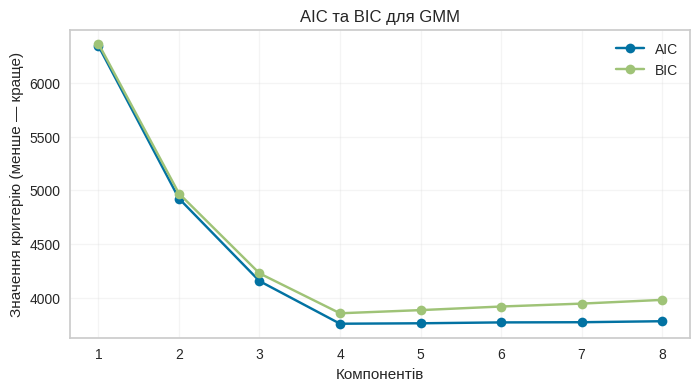

Кандидат за AIC: 4
Кандидат за BIC: 4


In [80]:
gmm_scores = []
for n in range(1, 9):
    gm = GaussianMixture(n_components=n, covariance_type='full',
                         n_init=3, random_state=RANDOM_STATE)
    gm.fit(X_gmm)
    gmm_scores.append({'Компонентів': n,
                       'AIC': gm.aic(X_gmm), 'BIC': gm.bic(X_gmm)})
score_table = pd.DataFrame(gmm_scores).set_index('Компонентів')
display(score_table.round(1))

score_table.plot(marker='o', figsize=(8, 4), title='AIC та BIC для GMM')
plt.xticks(score_table.index)
plt.ylabel('Значення критерію (менше — краще)')
plt.show()

print('Кандидат за AIC:', score_table['AIC'].idxmin())
print('Кандидат за BIC:', score_table['BIC'].idxmin())

###**Пояснення:**

За допомогою класу `GaussianMixture` із бібліотеки `scikit-learn` виконано автоматизований підбір оптимальної кількості гауссових компонентів для штучного набору даних `X_gmm`, який містить 500 об'єктів, розподілених навколо чотирьох центрів.

Для дослідження послідовно побудовано моделі `GMM` із кількістю компонентів від 1 до 8 (`n_components=n`). Для кожної моделі використано параметри `covariance_type='full'`, `n_init=3` та `random_state=42`, що забезпечують використання повних матриць коваріації, декількох ініціалізацій і відтворюваність результатів.

За допомогою методу `fit()` виконано навчання кожної моделі, після чого обчислено два критерії оцінювання якості:

`AIC` (`gm.aic()`) – інформаційний критерій, який оцінює якість відповідності моделі даним з урахуванням штрафу за кількість її параметрів.

`BIC` (`gm.bic()`) – байєсівський інформаційний критерій, який також враховує якість відповідності моделі та її складність, але за достатньо великої вибірки сильніше штрафує за збільшення кількості параметрів.

Для обох критеріїв менше значення відповідає кращому співвідношенню якості моделі та її складності серед порівнюваних варіантів.

Отримані результати збережено в таблиці `score_table`, а за допомогою методу `plot()` побудовано графік залежності значень `AIC` та `BIC` від кількості гауссових компонентів.

Для автоматичного визначення рекомендованої кількості компонентів використано метод `idxmin()`, який знаходить значення `K`, за якого відповідний інформаційний критерій досягає мінімуму.

**Аналіз отриманих результатів:**

Значення обох критеріїв суттєво зменшуються зі збільшенням кількості компонентів від 1 до 4.

Для `AIC` спостерігається зниження з 6340.5 при одній компоненті до мінімального значення 3761.7 при чотирьох компонентах.

Для `BIC` також спостерігається зменшення з 6361.5 до мінімального значення 3858.7 при `K=4`.

При подальшому збільшенні кількості компонентів від 5 до 8 значення обох критеріїв зростають, що свідчить про відсутність достатнього покращення відповідності моделі даним для виправдання її додаткової складності.

**Аналіз графіка `AIC` та `BIC`:**

На графіку відображено залежність значень інформаційних критеріїв від кількості гауссових компонентів.

Обидві криві мають виражену спадну тенденцію до `K=4`, після чого спостерігається їх незначне зростання.

Найнижчі точки обох кривих відповідають чотирьом компонентам, що вказує на узгодженість результатів двох критеріїв.

Крива `BIC` розташована вище за `AIC`, що пояснюється сильнішим штрафом за складність моделі для цього набору даних.

### 7.2. BayesianGaussianMixture

Тут `n_components` визначає **верхню межу** числа компонентів; ваги зайвих компонентів можуть наближатися до нуля. Поріг `0.01` нижче є лише практичною умовою для підрахунку «активних» компонентів, а не строгим статистичним правилом.

In [81]:
bgm = BayesianGaussianMixture(
    n_components=10, weight_concentration_prior_type='dirichlet_process',
    random_state=RANDOM_STATE, max_iter=500
)
bgm.fit(X_gmm)
print('Ваги 10 компонент:', np.round(bgm.weights_, 3))
print('Число компонент із вагою понад 1%:', int((bgm.weights_ > 0.01).sum()))

Ваги 10 компонент: [0.002 0.002 0.25  0.25  0.249 0.247 0.    0.    0.    0.   ]
Число компонент із вагою понад 1%: 4


###**Пояснення:**

За допомогою класу `BayesianGaussianMixture` із бібліотеки `scikit-learn` виконано байєсівську кластеризацію штучного набору даних `X_gmm`, який містить 500 об'єктів, розподілених навколо чотирьох центрів.

Для створення моделі використано параметри `n_components=10`, `weight_concentration_prior_type='dirichlet_process'`, `random_state=42` та `max_iter=500`.

Параметр `n_components=10` задає максимальну кількість гауссових компонентів, які може використовувати модель, а `weight_concentration_prior_type='dirichlet_process'` визначає застосування апроксимації процесу, що дозволяє зменшувати ваги компонентів, які не мають суттєвого внеску в розподіл даних.

Параметр `max_iter=500` встановлює максимальну кількість ітерацій навчання, а `random_state=42` забезпечує відтворюваність результатів.

За допомогою методу `fit()` виконано навчання моделі, під час якого оцінено параметри гауссових компонентів та їхні ваги.

Для аналізу результатів використано атрибут `weights_`, який містить ваги всіх десяти компонентів. За допомогою умови `bgm.weights_ > 0.01` визначено кількість практично активних компонентів, вага яких перевищує 1%.

**Аналіз отриманих результатів:**

У результаті навчання моделі отримано ваги десяти гауссових компонентів:

[0.002, 0.002, 0.250, 0.250, 0.249, 0.247, 0.000, 0.000, 0.000, 0.000]

Чотири компоненти мають найбільші ваги – 0.250, 0.250, 0.249 та 0.247, що свідчить про їхній основний внесок у формування загального розподілу даних.

Інші шість компонентів мають дуже малі ваги, близькі до нуля, тому їхній внесок у модель є незначним.

За встановленим порогом 0.01 (1%) модель визначила 4 активні компоненти з десяти можливих.

## 8. Перевірка якості та стабільності

**Відповідність лекції:** §9, §11.

Внутрішні індекси (`silhouette_score`, `calinski_harabasz_score`, `davies_bouldin_score`) працюють без еталонних міток. Зовнішні індекси (`adjusted_rand_score`, `adjusted_mutual_info_score`) можна обчислювати **після** кластеризації, якщо незалежні відомі категорії є в навчальному датасеті.

Числа 0, 1, 2 у мітках кластерів — умовні. Перестановка номерів не означає зміну розбиття; ARI до такої перестановки інваріантний.

In [82]:
print('Iris: ARI до відомих міток =',
      round(adjusted_rand_score(y_iris_reference, labels_iris_km), 3))
print('Iris: AMI до відомих міток =',
      round(adjusted_mutual_info_score(y_iris_reference, labels_iris_km), 3))

permuted = np.array([2, 0, 1])[labels_iris_km]
print('ARI після перестановки номерів кластерів =',
      adjusted_rand_score(labels_iris_km, permuted))

Iris: ARI до відомих міток = 0.62
Iris: AMI до відомих міток = 0.655
ARI після перестановки номерів кластерів = 1.0


###**Пояснення:**

За допомогою функцій `adjusted_rand_score()` та `adjusted_mutual_info_score()` із бібліотеки `scikit-learn` виконано зовнішнє оцінювання якості кластеризації набору даних `Iris` шляхом порівняння отриманих кластерів `K-means` зі справжніми мітками класів.

Для оцінювання використано збережені еталонні мітки `y_iris_reference` та результати кластеризації `labels_iris_km`, отримані раніше за допомогою алгоритму `KMeans` із трьома кластерами.

`Adjusted Rand Index` (`ARI`) – метрика, яка оцінює узгодженість двох розбиттів на основі пар об'єктів з урахуванням випадкових збігів. Значення 1 відповідає повному збігу розбиттів, а значення близько 0 – узгодженості на рівні випадкового розподілу.

`Adjusted Mutual Information` (`AMI`) – метрика, яка оцінює спільну інформацію між двома розбиттями з поправкою на випадкові збіги. Значення 1 відповідає повній узгодженості, а значення близько 0 – відсутності суттєвої узгодженості понад випадковий рівень.

Додатково за допомогою виразу `np.array([2, 0, 1])[labels_iris_km]` виконано перестановку номерів кластерів, за якої початкові мітки 0, 1 та 2 замінено на 2, 0 та 1 відповідно.

Після перестановки повторно обчислено метрику `adjusted_rand_score()`, щоб перевірити її незалежність від числових позначень кластерів.

**Аналіз отриманих результатів:**

У результаті порівняння кластерів `K-means` зі справжніми мітками набору `Iris` отримано `ARI = 0.620`, що свідчить про помітну, але неповну узгодженість кластерного розбиття з еталонними класами.

Значення `AMI = 0.655` також підтверджує наявність суттєвої спільної інформації між отриманими кластерами та справжніми видами ірисів.

Отримані показники свідчать про те, що алгоритм `KMeans` зміг відтворити основну структуру набору даних, проте частина об'єктів була згрупована не відповідно до їхніх справжніх класів.

Після перестановки номерів кластерів отримано `ARI = 1.0` при порівнянні початкового та перенумерованого розбиттів.

Це підтверджує, що метрика `ARI` не залежить від числових позначень кластерів, а враховує лише те, які об'єкти належать до однакових або різних груп.

### 8.1. Чутливість до ініціалізації

Для K-means треба зафіксувати `random_state` і `n_init`, а під час дослідження стійкості — **свідомо змінювати** ініціалізацію. Якщо різні запуски дають однакову інерцію й ARI близький до 1, це один з аргументів на користь стійкості розбиття, але не гарантія його прикладної корисності.

In [83]:
stability_labels = []
stability_rows = []
for seed in [7, 21, 42, 101, 202]:
    model = KMeans(n_clusters=3, n_init=1, random_state=seed)
    labels = model.fit_predict(X_wine)
    stability_labels.append(labels)
    stability_rows.append({'random_state': seed, 'WCSS': model.inertia_,
                           'Silhouette': silhouette_score(X_wine, labels)})
print('Порівняння запусків із n_init=1:')
display(pd.DataFrame(stability_rows).round(3))
print('ARI між першим запуском і рештою:',
      [round(adjusted_rand_score(stability_labels[0], labs), 3)
       for labs in stability_labels[1:]])

Порівняння запусків із n_init=1:


,random_state,WCSS,Silhouette
0,7,1278.761,0.286
1,21,1277.928,0.285
2,42,1277.928,0.285
3,101,1277.928,0.285
4,202,1279.731,0.283


ARI між першим запуском і рештою: [0.982, 0.982, 0.982, 0.947]


###**Пояснення:**

За допомогою алгоритму `KMeans` із бібліотеки `scikit-learn` виконано дослідження чутливості результатів кластеризації до випадкової ініціалізації на наборі даних `Wine` з використанням попередньо стандартизованих ознак `X_wine`.

Для дослідження виконано п'ять незалежних запусків алгоритму з різними значеннями параметра `random_state`: 7, 21, 42, 101 та 202.

Для всіх запусків задано однакову кількість кластерів (`n_clusters=3`) та параметр `n_init=1`, який передбачає лише одну ініціалізацію центроїдів під час кожного запуску. Це дозволяє оцінити вплив випадкового вибору початкових центрів на результати кластеризації.

За допомогою методу `fit_predict()` виконано навчання моделей та визначено належність об'єктів до відповідних кластерів.

Для оцінювання результатів кожного запуску використано показники `WCSS` (`inertia_`) та `Silhouette` (`silhouette_score`), які характеризують внутрішньокластерне розсіювання, компактність і відокремленість сформованих груп.

Додатково за допомогою функції `adjusted_rand_score()` обчислено `Adjusted Rand Index` (`ARI`) між результатами першого запуску (`random_state=7`) та кожним із наступних запусків для оцінювання стабільності кластерного розбиття.

**Аналіз отриманих результатів:**

Для запусків із `random_state=21, 42` та `101` отримано однакові значення `WCSS = 1277.928`  та `Silhouette = 0.285`, що свідчить про однакову якість сформованих кластерів за цими метриками.

Для першого запуску (`random_state=7`) отримано `WCSS` = 1278.761 та `Silhouette` = 0.286. Значення `WCSS` є дещо вищим, проте коефіцієнт силуету незначно перевищує показники інших запусків.

Найбільше значення `WCSS` 1279.731 та найменше значення `Silhouette` 0.283 отримано при `random_state=202`, що свідчить про дещо менш сприятливе розбиття за обома показниками.

Загалом значення `WCSS` змінюються в межах 1277.928–1279.731, а `Silhouette` – 0.283–0.286, що вказує на незначні відмінності між результатами п'яти запусків.

**Аналіз стабільності за метрикою `ARI`:**

За результатами порівняння першого запуску з наступними отримано значення `ARI`:

* random_state=21 – ARI = 0.982;

* random_state=42 – ARI = 0.982;

* random_state=101 – ARI = 0.982;

* random_state=202 – ARI = 0.947.

Усі отримані значення `ARI` є близькими до 1, що свідчить про високу узгодженість кластерних розбиттів за різних випадкових ініціалізацій.

Найменше значення `ARI` 0.947 спостерігається при `random_state=202`, що вказує на дещо більшу відмінність сформованих кластерів порівняно з першим запуском.

Водночас значення `ARI`, менші за 1, свідчать про те, що результати не є повністю ідентичними та належність окремих об'єктів до кластерів може змінюватися залежно від початкового розташування центроїдів.

## 9. Наскрізний приклад: змістовна інтерпретація кластерів Wine

**Відповідність лекції:** §10.

Порівняння геометричних індексів — **не кінцева мета**. Для предметного висновку потрібно:

1. обґрунтувати кандидатне K за кількома критеріями;
2. побудувати кластеризацію на стандартизованих ознаках;
3. повернутися до початкових одиниць вимірювання і проаналізувати типові значення ознак;
4. повідомити розміри кластерів, а також результати альтернативного алгоритму.

Нижче для *ілюстрації профілювання* використаємо `K=3`. Це не твердження, що три групи завжди оптимальні за кожним індексом.

In [84]:
k_wine_demo = 3
wine_model = KMeans(n_clusters=k_wine_demo, n_init=10,
                    random_state=RANDOM_STATE)
labels_wine_demo = wine_model.fit_predict(X_wine)

profile_wine = (features_wine.assign(cluster=labels_wine_demo)
                .groupby('cluster').mean())
sizes_wine = pd.Series(labels_wine_demo).value_counts().sort_index()
center_original_units = pd.DataFrame(
    scaler_wine.inverse_transform(wine_model.cluster_centers_),
    columns=features_wine.columns
)

print('Кількість об’єктів за групами:')
display(sizes_wine.rename('Кількість').to_frame())
print('Середній профіль (в оригінальних одиницях):')
display(profile_wine[['alcohol', 'flavanoids', 'proline']].round(2))
print('Центри зворотно перетворені в початковий масштаб:')
display(center_original_units[['alcohol', 'flavanoids', 'proline']].round(2))

Кількість об’єктів за групами:


,Кількість
0,65
1,51
2,62


Середній профіль (в оригінальних одиницях):


,alcohol,flavanoids,proline
cluster,,,
0,12.25,2.05,510.17
1,13.13,0.82,619.06
2,13.68,3.00,1100.23


Центри зворотно перетворені в початковий масштаб:


,alcohol,flavanoids,proline
0,12.25,2.05,510.17
1,13.13,0.82,619.06
2,13.68,3.00,1100.23


###**Пояснення:**

За допомогою алгоритму `KMeans` із бібліотеки `scikit-learn` виконано кластеризацію набору даних `Wine` на три кластери (`n_clusters=3`) із використанням 13 попередньо стандартизованих ознак `X_wine`.

Для навчання моделі задано параметри `n_init=10` та `random_state=42`, які забезпечують використання декількох незалежних ініціалізацій центроїдів і відтворюваність результатів.

За допомогою методу `fit_predict()` визначено належність кожного з 178 об'єктів до відповідного кластера.

Для змістовної інтерпретації отриманих груп використано початкові значення ознак `features_wine`, до яких за допомогою методу `assign()` додано мітки сформованих кластерів.

Методи `groupby('cluster')` та `mean()` використано для обчислення середніх значень ознак у кожному кластері, а метод `value_counts()` – для визначення кількості об'єктів у сформованих групах.

Додатково за допомогою методу `inverse_transform()` класу `StandardScaler` виконано зворотне перетворення центроїдів кластерів із стандартизованого масштабу до початкових одиниць вимірювання.

Для аналізу вибрано три характеристики хімічного складу вина: `alcohol` (вміст алкоголю), `flavanoids` (вміст флавоноїдів) та `proline` (вміст проліну).

**Аналіз отриманих результатів:**

У результаті кластеризації сформовано три кластери з такою кількістю об'єктів:

* Кластер 0 – 65 об'єктів;

* Кластер 1 – 51 об'єкт;

* Кластер 2 – 62 об'єкти.

Отримані результати свідчать про відносно рівномірний розподіл об'єктів між трьома групами, хоча їхні розміри дещо відрізняються.

**Аналіз середніх профілів кластерів:**

Кластер 0 характеризується найнижчим середнім вмістом алкоголю (12.25) та проліну (510.17). Середній вміст флавоноїдів становить 2.05, що відповідає проміжному значенню серед трьох сформованих груп.

Кластер 1 має середній вміст алкоголю 13.13, найнижчий вміст флавоноїдів (0.82) та середній вміст проліну 619.06. Основною відмінністю цієї групи є значно нижча концентрація флавоноїдів порівняно з іншими кластерами.

Кластер 2 характеризується найвищими середніми значеннями всіх трьох досліджуваних ознак: вміст алкоголю становить 13.68, флавоноїдів – 3.00, а проліну – 1100.23. Це свідчить про суттєві відмінності хімічного складу вин цієї групи порівняно з іншими кластерами.

**Аналіз центроїдів у початковому масштабі:**

Після застосування методу `inverse_transform()` отримано координати центроїдів кластерів у початкових одиницях вимірювання.

Значення центроїдів практично збігаються із середніми профілями відповідних кластерів, оскільки алгоритм `KMeans` визначає центроїд як середнє значення ознак усіх об'єктів, що належать до відповідної групи.

Зворотне перетворення дозволяє інтерпретувати результати кластеризації за реальними характеристиками вина, а не за стандартизованими значеннями, які використовувалися під час навчання моделі.

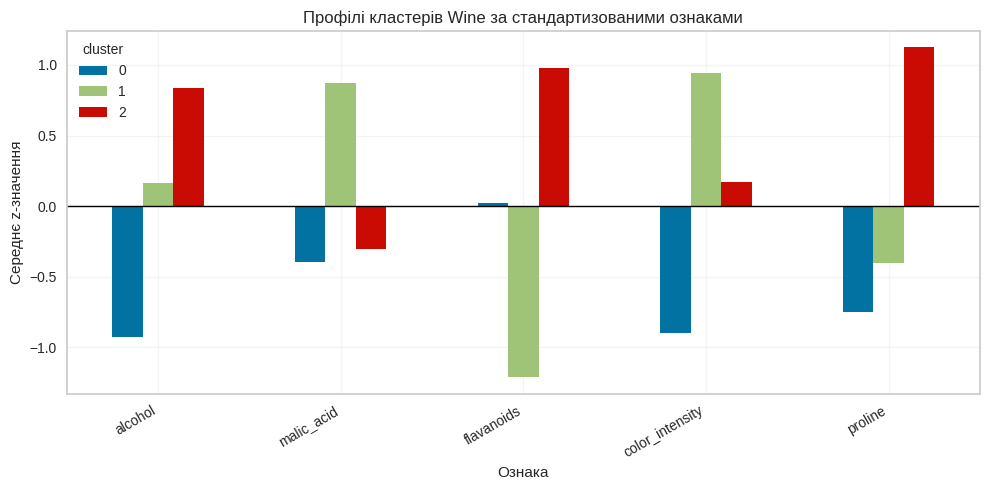

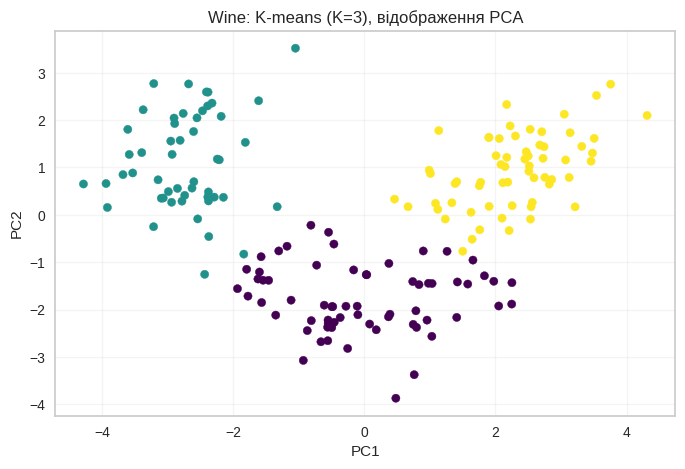

In [85]:
# Профілі стандартизованих середніх: значення > 0 вище за середнє у вибірці.
profile_scaled = pd.DataFrame(X_wine, columns=features_wine.columns)
profile_scaled['cluster'] = labels_wine_demo
profile_scaled = profile_scaled.groupby('cluster').mean()

selected_features = ['alcohol', 'malic_acid', 'flavanoids', 'color_intensity', 'proline']
profile_scaled[selected_features].T.plot(kind='bar', figsize=(10, 5))
plt.axhline(0, color='black', linewidth=1)
plt.title('Профілі кластерів Wine за стандартизованими ознаками')
plt.ylabel('Середнє z-значення')
plt.xlabel('Ознака')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

wine_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_wine)
plt.scatter(wine_2d[:, 0], wine_2d[:, 1], c=labels_wine_demo,
            cmap='viridis', s=35)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Wine: K-means (K=3), відображення PCA')
plt.show()

###**Пояснення:**

За допомогою бібліотеки `pandas` створено таблицю `profile_scaled`, яка містить 13 стандартизованих ознак набору даних `Wine` та мітки кластерів `labels_wine_demo`, отримані раніше за допомогою алгоритму `KMeans` із трьома кластерами (`K=3`).

За допомогою методів `groupby('cluster')` та `mean()` обчислено середні стандартизовані значення ознак для кожного кластера, що дозволяє порівняти характеристики сформованих груп відносно загального середнього рівня у вибірці.

Для аналізу вибрано п'ять ознак: `alcohol` (вміст алкоголю), `malic_acid` (вміст яблучної кислоти), `flavanoids` (вміст флавоноїдів), `color_intensity` (інтенсивність забарвлення) та `proline` (вміст проліну).

За допомогою методу `plot(kind='bar')` побудовано стовпчикову діаграму середніх стандартизованих значень ознак для трьох кластерів.

Горизонтальна чорна лінія, побудована за допомогою `plt.axhline(0)`, позначає нульовий рівень, який відповідає середньому значенню відповідної ознаки в усьому наборі даних. Додатні значення вказують на перевищення загального середнього рівня, а від'ємні – на значення нижче середнього.

Додатково за допомогою методу головних компонент `PCA` (`n_components=2`) виконано зменшення розмірності стандартизованих даних із 13 до двох компонентів для двовимірної візуалізації результатів кластеризації.

За допомогою функції `plt.scatter()` побудовано графік розсіювання, на якому об'єкти позначено різними кольорами відповідно до їхньої належності до кластерів `KMeans`.

**Аналіз профілів кластерів за стандартизованими ознаками:**

На першому графіку відображено середні стандартизовані значення п'яти хімічних характеристик вина для трьох сформованих кластерів.

Кластер 0 (синій колір) характеризується значеннями `alcohol`, `malic_acid`, `color_intensity` та `proline` нижче загального середнього рівня. Водночас значення `flavanoids` є близьким до нуля, що свідчить про середній рівень цієї ознаки. Найбільші від'ємні відхилення спостерігаються для вмісту алкоголю та інтенсивності забарвлення.

Кластер 1 (зелений колір) характеризується підвищеними значеннями `malic_acid` та `color_intensity`, тоді як `flavanoids` має найбільше від'ємне відхилення серед усіх трьох кластерів. Значення `proline` також нижче середнього рівня, а `alcohol` незначно перевищує загальне середнє значення.

Кластер 2 (червоний колір) має найвищі стандартизовані значення `alcohol`, `flavanoids` та `proline`. Особливо помітне перевищення середнього рівня за вмістом проліну та флавоноїдів. Водночас значення `malic_acid` є нижчим за середнє, а `color_intensity` – дещо вищим.

Отримані результати демонструють, що кластери мають різні профілі хімічних характеристик, а найбільш виражені відмінності між ними спостерігаються за вмістом флавоноїдів, проліну, яблучної кислоти та інтенсивністю забарвлення.

**Аналіз `PCA`-проєкції кластерів `Wine`:**

На другому графіку відображено результати кластеризації набору даних `Wine` алгоритмом `KMeans` (`K=3`) у двовимірному просторі головних компонент `PC1` та `PC2`.

Чітко простежуються три основні групи об'єктів, позначені різними кольорами відповідно до їхньої кластерної належності.

Кластер 0 (фіолетові точки) розташований переважно в нижній центральній частині графіка та характеризується від'ємними значеннями другої головної компоненти PC2.

Кластер 1 (бірюзові точки) зосереджений переважно в лівій верхній частині графіка, маючи здебільшого від'ємні значення `PC1` та додатні значення `PC2`.

Кластер 2 (жовті точки) розташований переважно в правій верхній частині графіка та характеризується додатними значеннями першої головної компоненти `PC1`.

Між сформованими групами спостерігається достатньо виражене просторове розділення, проте окремі об'єкти розташовані поблизу меж кластерів, що свідчить про часткове перекриття їхніх областей у `PCA`-проєкції.

Водночас `PCA` використовується лише для візуалізації, оскільки кластеризацію виконано на основі всіх 13 стандартизованих ознак.

### 9.1. Порівняння з Ward і DBSCAN

Щоб порівнювати алгоритми коректно, застосовуємо **одні й ті самі стандартизовані дані**. `ARI` нижче вимірює узгодженість двох кластерних розбиттів, а не «точність» одного з них. Для DBSCAN додатково вказуємо частку шуму.

ARI між K-means і Ward: 0.853
DBSCAN → груп без шуму: 2
DBSCAN → частка шуму: 0.309


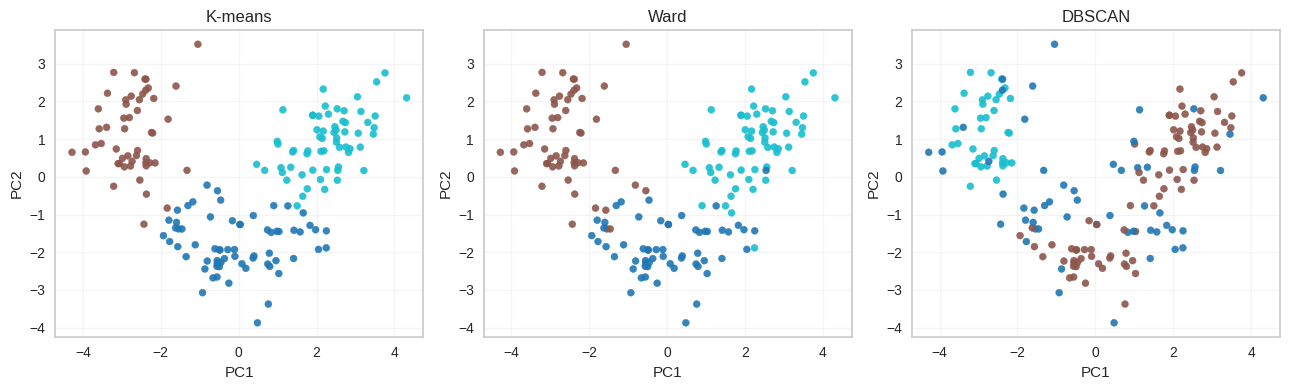

In [86]:
labels_wine_ward = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_wine)
labels_wine_db = DBSCAN(eps=2.2, min_samples=5).fit_predict(X_wine)

print('ARI між K-means і Ward:',
      round(adjusted_rand_score(labels_wine_demo, labels_wine_ward), 3))
print('DBSCAN → груп без шуму:', len(set(labels_wine_db) - {-1}))
print('DBSCAN → частка шуму:', round(np.mean(labels_wine_db == -1), 3))

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for axes, labels, name in zip(ax,
    [labels_wine_demo, labels_wine_ward, labels_wine_db],
    ['K-means', 'Ward', 'DBSCAN']):
    axes.scatter(wine_2d[:, 0], wine_2d[:, 1], c=labels,
                 cmap='tab10', s=25, alpha=0.9)
    axes.set(title=name, xlabel='PC1', ylabel='PC2')
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою алгоритмів `AgglomerativeClustering` та `DBSCAN` із бібліотеки `scikit-learn` виконано кластеризацію набору даних `Wine` з використанням 13 попередньо стандартизованих ознак `X_wine`.

Для ієрархічної агломеративної кластеризації використано метод `Ward` із параметрами `n_clusters=3` та `linkage='ward'`, який послідовно об'єднує об'єкти у групи з мінімальним приростом внутрішньокластерного розсіювання.

Алгоритм `DBSCAN` застосовано з параметрами `eps=2.2` та `min_samples=5`, які визначають радіус околу точки та мінімальну кількість об'єктів для формування щільної області.

За допомогою методу `fit_predict()` виконано кластеризацію обома алгоритмами та визначено належність об'єктів до відповідних груп.

Для порівняння результатів `KMeans` та `Ward` використано метрику `Adjusted Rand Index` (`adjusted_rand_score`), яка оцінює ступінь узгодженості двох кластерних розбиттів з урахуванням випадкових збігів.

Для алгоритму `DBSCAN` додатково обчислено кількість кластерів без урахування шуму та частку шумових точок, які позначаються міткою -1.

За допомогою методу `plt.subplots()` побудовано три графіки розсіювання, на яких відображено результати алгоритмів `KMeans`, `Ward` та `DBSCAN` у двовимірному просторі головних компонент `PC1` та `PC2`, отриманому раніше методом `PCA`.

**Аналіз отриманих результатів:**

У результаті порівняння алгоритмів `KMeans` та `Ward` отримано значення `ARI` = 0.853, що свідчить про високу узгодженість сформованих кластерних розбиттів.

Це означає, що обидва алгоритми віднесли більшість об'єктів до аналогічних груп, хоча належність окремих спостережень до кластерів може відрізнятися.

Алгоритм `DBSCAN` сформував 2 кластери без урахування шумових точок.

Частка шуму становить 0.309 (30.9%), що відповідає приблизно 55 об'єктам із 178, які не були віднесені до жодного кластера.

Отриманий результат свідчить про те, що за вибраних параметрів `DBSCAN` значну частину спостережень визначив як шум.

**Аналіз графіка `KMeans`:**

На першому графіку відображено результати кластеризації алгоритмом `KMeans` (`K=3`).

Спостерігаються три основні групи об'єктів, розташовані переважно в лівій верхній, нижній центральній та правій верхній частинах `PCA`-проєкції.

Кластери мають відносно чітку структуру, проте між окремими групами спостерігається часткове перекриття, особливо в центральній області графіка.

**Аналіз графіка `Ward`:**

На другому графіку відображено результати ієрархічної агломеративної кластеризації методом `Ward`.

Алгоритм також сформував три основні групи, які за своїм розташуванням та складом значною мірою відповідають результатам `KMeans`.

Водночас помітні незначні відмінності у віднесенні окремих об'єктів до кластерів, переважно поблизу меж між групами.

Висока подібність двох графіків узгоджується з отриманим значенням `ARI = 0.853`, яке підтверджує значну узгодженість результатів `KMeans` та `Ward`.

**Аналіз графіка `DBSCAN`:**

На третьому графіку відображено результати щільнісної кластеризації алгоритмом `DBSCAN`.

На відміну від `KMeans` та `Ward`, алгоритм виділив лише два кластери, які охоплюють окремі щільні області набору даних.

Значна кількість точок позначена окремим кольором і відповідає шумовим спостереженням із міткою -1.

Шумові точки розташовані в різних частинах `PCA`-проєкції, зокрема поблизу сформованих кластерів та між ними. Це свідчить про те, що частина об'єктів не задовольняє встановлені критерії щільності в початковому 13-вимірному просторі ознак.

**Порівняння отриманих результатів:**

Алгоритми `KMeans` та `Ward` сформували по три кластери, які мають високий ступінь узгодженості за метрикою `ARI` та подібну просторову структуру на `PCA`-проєкції.

Натомість `DBSCAN` за заданих параметрів сформував лише два кластери та визначив значну частку шумових точок (30.9%), що свідчить про суттєві відмінності його розбиття від результатів інших алгоритмів.

## 10. Підсумок навчального прикладу

**У цьому ноутбуці продемонстровано:**

| Призначення | Алгоритм / метод | Вбудований інструмент |
|:--|:--|:--|
| Центроїдна кластеризація | K-means | `KMeans`, `.labels_`, `.cluster_centers_`, `.inertia_` |
| Прискорення / поділ груп | Mini-batch / bisecting | `MiniBatchKMeans`, `BisectingKMeans` |
| Ієрархія | Ward + дендрограма | `AgglomerativeClustering`, `scipy.cluster.hierarchy` |
| Щільність | DBSCAN, OPTICS, HDBSCAN | `DBSCAN`, `OPTICS`, `HDBSCAN` |
| Моди щільності | Mean Shift | `MeanShift`, `estimate_bandwidth` |
| Альтернативні підходи | Affinity, BIRCH, Spectral | однойменні класи `sklearn.cluster` |
| Імовірнісні компоненти | GMM | `GaussianMixture`, `.aic()`, `.bic()` |
| Неефективні компоненти | Bayesian GMM | `BayesianGaussianMixture`, `.weights_` |
| Вибір K / якість | лікоть, силует, CH, DB | `.inertia_`, `silhouette_score`, `calinski_harabasz_score`, `davies_bouldin_score` |
| Автоматизація аналізу ліктя | KneeLocator, Yellowbrick | *додаткові* `kneed` і `yellowbrick` |

**Головний методичний висновок:** жоден внутрішній індекс окремо не гарантує «правильного» $K$. Обґрунтовуйте вибір через кілька критеріїв, властивості даних, стійкість груп і змістовність їхніх профілів. Не плутайте номер кластера з реальною категорією.

---
# Самостійне завдання для студентів — одне комплексне завдання

## Дослідження кластерної структури рукописних цифр (`load_digits`)

**Мета:** самостійно провести повний цикл кластеризації на **новому** вбудованому наборі даних, який не використовувався в демонстраційних прикладах ноутбука і не збігається з лабораторною роботою про опосумів.

**Умова завдання.** Завантажте `sklearn.datasets.load_digits` (1797 зображень рукописних цифр, кожне подано 64 числовими ознаками). Розглядайте це як **задачу навчання без учителя**: під час вибору числа кластерів та навчання **не використовуйте** еталонні значення цифр `target`.

Виконайте повний аналіз: перевірте структуру й масштаб ознак, за потреби виконайте стандартизацію; дослідіть `KMeans` на діапазоні $K=2,\ldots,12$; побудуйте графік ліктя та графіки силуету, CH і DB; обґрунтуйте одне кандидатне число кластерів (розбіжності критеріїв треба пояснити); побудуйте фінальне розбиття й порівняйте його з `AgglomerativeClustering`; відобразіть точки в PCA-проєкції та оцініть розміри отриманих груп. **Лише після завершення кластеризації** можете використати відомі мітки `target` для додаткового розрахунку ARI й пояснити, чому отримані кластери не зобов'язані відповідати десяти цифрам.

**Результат здачі:** один виконаний `.ipynb` із кодом, графіками, таблицею критеріїв та коротким академічним висновком (8–12 речень), у якому наведено обране $K$, аргументи на користь вибору, порівняння двох алгоритмів та застереження щодо інтерпретації.

> Самостійний етап навмисно **не містить готового розв'язання**. Наступна комірка лише завантажує дані; весь аналіз студент пише самостійно.

###**1. Завантаження набору даних load_digits**

In [87]:
# Початкова комірка самостійного завдання (без розв'язання)
from sklearn.datasets import load_digits

digits = load_digits()
X_digits_raw = digits.data
# y_digits_reference = digits.target  # НЕ використовувати до завершення кластеризації!

print('Розмірність даних:', X_digits_raw.shape)
print('Початковий діапазон значень:', X_digits_raw.min(), '...', X_digits_raw.max())
# Далі: ваш код дослідження, візуалізації, оцінювання та висновків.

Розмірність даних: (1797, 64)
Початковий діапазон значень: 0.0 ... 16.0


###**2. Первинний аналіз набору даних load_digits**

In [88]:
# Первинний аналіз набору даних load_digits

features_digits = pd.DataFrame(
    X_digits_raw,
    columns = digits.feature_names
)

print("Розмірність набору даних:", features_digits.shape)
print("Кількість пропущених значень:",
      features_digits.isna().sum().sum())
print("Кількість числових ознак:",
      features_digits.shape[1])

print("\nОсновні статистичні характеристики:")
display(features_digits.describe().round(2))

print("\nПерші 5 об'єктів:")
display(features_digits.head())

Розмірність набору даних: (1797, 64)
Кількість пропущених значень: 0
Кількість числових ознак: 64

Основні статистичні характеристики:


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,...,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
count,1797.0,1797.00,1797.00,1797.00,1797.00,1797.00,1797.00,...,1797.00,1797.00,1797.00,1797.00,1797.00,1797.00,1797.00
mean,0.0,0.30,5.20,11.84,11.85,5.78,1.36,...,0.28,5.56,12.09,11.81,6.76,2.07,0.36
std,0.0,0.91,4.75,4.25,4.29,5.67,3.33,...,0.93,5.10,4.37,4.93,5.90,4.09,1.86
min,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.0,0.00,1.00,10.00,10.00,0.00,0.00,...,0.00,1.00,11.00,10.00,0.00,0.00,0.00
50%,0.0,0.00,4.00,13.00,13.00,4.00,0.00,...,0.00,4.00,13.00,14.00,6.00,0.00,0.00
75%,0.0,0.00,9.00,15.00,15.00,11.00,0.00,...,0.00,10.00,16.00,16.00,12.00,2.00,0.00
max,0.0,8.00,16.00,16.00,16.00,16.00,16.00,...,9.00,16.00,16.00,16.00,16.00,16.00,16.00



Перші 5 об'єктів:


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,...,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,...,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,...,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,...,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,...,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,...,0.0,0.0,2.0,16.0,4.0,0.0,0.0


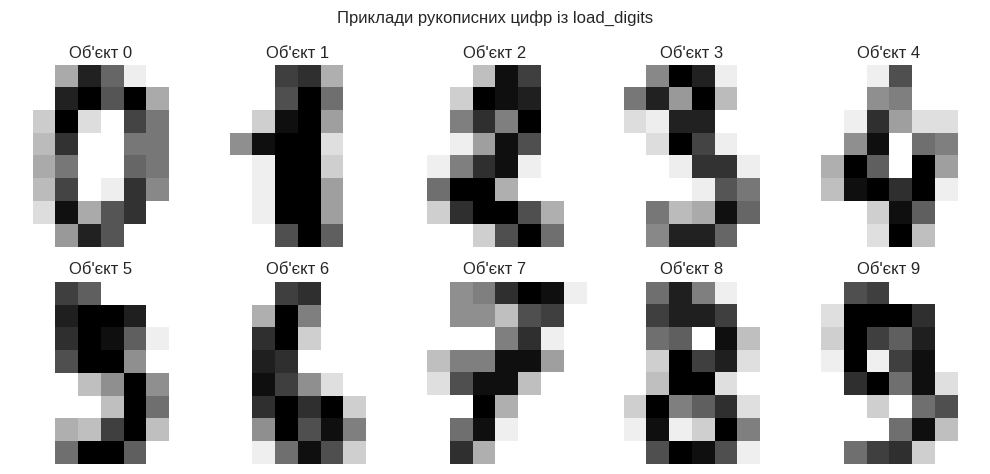

In [89]:
# Візуалізація перших 10 зображень рукописних цифр

fig, axes = plt.subplots(2, 5, figsize = (10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap = 'gray_r')
    ax.set_title(f"Об'єкт {i}")
    ax.axis('off')

plt.suptitle('Приклади рукописних цифр із load_digits')
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою бібліотеки `pandas` створено таблицю `features_digits` на основі масиву `X_digits_raw`, який містить числові характеристики зображень рукописних цифр із набору даних `load_digits`.

Для формування назв стовпців використано атрибут `digits.feature_names`, який містить позначення пікселів зображень у форматі `pixel_0_0`, `pixel_0_1` тощо.

За допомогою атрибута `shape` визначено розмірність набору даних, а методом `isna().sum().sum()` перевірено наявність пропущених значень.

Для дослідження розподілу числових ознак використано метод `describe()`, який обчислює основні статистичні характеристики: кількість значень, середнє арифметичне, стандартне відхилення, мінімум, максимум та квартилі.

За допомогою методу `head()` виведено перші п'ять об'єктів набору даних для ознайомлення з його структурою.

Додатково за допомогою функцій `plt.subplots()` та `imshow()` із бібліотеки `matplotlib` побудовано візуалізацію перших 10 зображень рукописних цифр у вигляді сітки з двох рядків і п'яти стовпців.

Для відображення використано параметр `cmap='gray_r'`, який задає інвертовану градацію сірого кольору. Підписи зображень відповідають порядковим номерам об'єктів у наборі даних, а не їхнім еталонним класам.

**Аналіз статистичних характеристик:**

У результаті виконання коду отримано розмірність набору даних (1797, 64), що підтверджує наявність 1797 зображень рукописних цифр, кожне з яких описується 64 числовими ознаками.

Кількість пропущених значень становить 0, тому додаткове заповнення або видалення пропусків не потрібне.

Значення пікселів перебувають у діапазоні від 0 до 16, де 0 відповідає найменшій інтенсивності пікселя, а 16 – найбільшій.

За результатами методу `describe()` встановлено, що середні значення та стандартні відхилення ознак суттєво відрізняються.

Наприклад, ознака `pixel_0_0` має середнє значення та стандартне відхилення 0, що свідчить про відсутність змін цього пікселя в усіх зображеннях. Натомість для ознак `pixel_0_3` та `pixel_0_4` середні значення становлять приблизно 11.84 та 11.85, а стандартні відхилення – 4.25 та 4.29 відповідно.

Це демонструє, що окремі ділянки зображень містять більше інформації про форму цифр, тоді як деякі пікселі залишаються незмінними.

**Аналіз візуалізації рукописних цифр:**

На графіку відображено перші 10 зображень набору даних `load_digits`, кожне з яких має розмір 8×8 пікселів.

Зображення представлені у градаціях сірого кольору, де різна інтенсивність пікселів формує контури рукописних символів.

Чітко простежуються відмінності у формі, нахилі та розташуванні окремих штрихів, які дозволяють візуально розрізняти цифри.

Водночас деякі символи мають подібні геометричні елементи, що може ускладнювати їх автоматичне групування за допомогою алгоритмів кластеризації.

###**3. Стандартизація ознак набору даних load_digits**

In [90]:
# Стандартизація ознак набору даних load_digits

scaler_digits = StandardScaler()
X_digits = scaler_digits.fit_transform(X_digits_raw)

print("Розмірність стандартизованих даних:", X_digits.shape)

print("\nСередні значення стандартизованих ознак:")
print(np.round(X_digits.mean(axis = 0), 3))

print("\nСтандартні відхилення стандартизованих ознак:")
print(np.round(X_digits.std(axis = 0), 3))

print("\nМінімальне та максимальне значення:")
print("Min:", round(X_digits.min(), 3))
print("Max:", round(X_digits.max(), 3))

print("\nКількість ознак із нульовою дисперсією:",
      np.sum(X_digits_raw.std(axis=0) == 0))

Розмірність стандартизованих даних: (1797, 64)

Середні значення стандартизованих ознак:
[ 0. -0. -0. -0.  0. -0. -0.  0. -0.  0. -0.  0.  0. -0.  0. -0. -0. -0.
  0.  0.  0. -0. -0. -0.  0.  0. -0. -0. -0. -0. -0. -0.  0.  0.  0. -0.
 -0. -0. -0.  0.  0. -0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0. -0.  0.  0.  0. -0. -0.  0.  0. -0.]

Стандартні відхилення стандартизованих ознак:
[0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 0. 1. 1. 1. 1. 1. 1. 0. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Мінімальне та максимальне значення:
Min: -3.013
Max: 42.379

Кількість ознак із нульовою дисперсією: 3


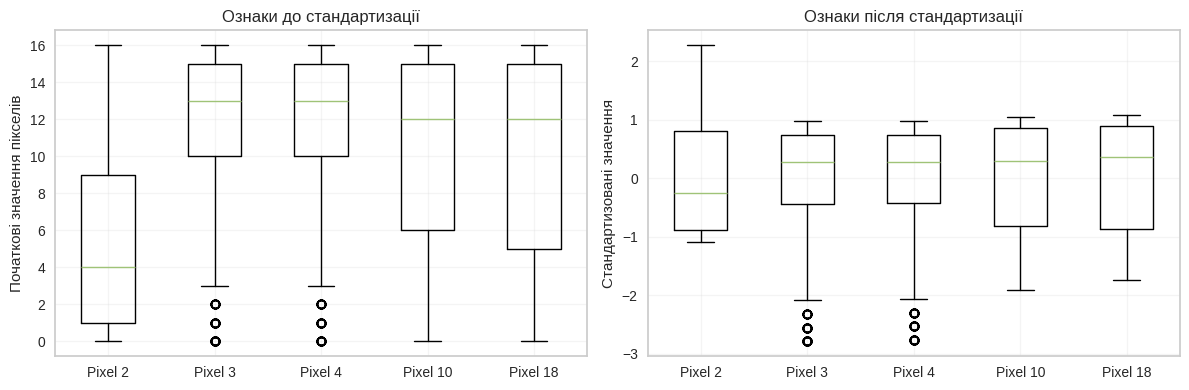

In [91]:
# Порівняння ознак до та після стандартизації

selected_pixels = [2, 3, 4, 10, 18]

fig, axes = plt.subplots(1, 2, figsize = (12, 4))

axes[0].boxplot(
    X_digits_raw[:, selected_pixels],
    tick_labels = [f"Pixel {i}" for i in selected_pixels]
)
axes[0].set_title("Ознаки до стандартизації")
axes[0].set_ylabel("Початкові значення пікселів")

axes[1].boxplot(
    X_digits[:, selected_pixels],
    tick_labels=[f"Pixel {i}" for i in selected_pixels]
)
axes[1].set_title("Ознаки після стандартизації")
axes[1].set_ylabel("Стандартизовані значення")

plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою класу `StandardScaler` із бібліотеки `scikit-learn` виконано стандартизацію 64 числових ознак набору даних `load_digits`, який містить 1797 зображень рукописних цифр.

Для перетворення використано метод `fit_transform()`, який обчислює середнє значення та стандартне відхилення кожної ознаки, після чого приводить їх до стандартизованого масштабу із середнім значенням 0 та стандартним відхиленням 1 для ознак із ненульовою дисперсією.

За допомогою методів `mean()` та `std()` перевірено середні значення та стандартні відхилення ознак після стандартизації. Додатково визначено мінімальне й максимальне значення стандартизованих даних, а також кількість ознак із нульовою дисперсією.

Для порівняння розподілів до та після стандартизації вибрано п'ять ознак із індексами 2, 3, 4, 10 та 18. За допомогою функції `boxplot()` із бібліотеки `matplotlib` побудовано дві діаграми розмаху, які відображають медіани, міжквартильні інтервали, розкид значень та потенційні викиди.

**Аналіз результатів стандартизації:**

У результаті виконання коду отримано розмірність стандартизованого набору даних (1797, 64), що підтверджує збереження початкової кількості об'єктів та ознак.

Середні значення всіх стандартизованих ознак практично дорівнюють 0, що свідчить про коректне виконання центрування даних.

Стандартні відхилення більшості ознак дорівнюють 1, проте для трьох ознак залишаються нульовими, оскільки їхні значення є незмінними для всіх об'єктів набору даних.

Отримано 3 ознаки з нульовою дисперсією, які не містять інформації для розрізнення зображень і після стандартизації залишаються нульовими.

Мінімальне значення стандартизованих даних становить -3.013, а максимальне – 42.379.

Велике максимальне значення пояснюється тим, що деякі пікселі переважно мають нульову або дуже низьку інтенсивність, але в окремих зображеннях набувають значно більших значень. Після ділення на невелике стандартне відхилення такі спостереження можуть отримувати великі стандартизовані значення.

**Аналіз графіка ознак до стандартизації:**

На першому графіку відображено розподіли початкових значень п'яти вибраних пікселів у діапазоні від 0 до 16.

Спостерігаються відмінності між медіанами та міжквартильними інтервалами ознак. Зокрема, для `Pixel 2` медіана становить приблизно 4, тоді як для `Pixel 3` і `Pixel 4` – близько 13, а для `Pixel 10` та `Pixel 18` – приблизно 12.

Для ознак `Pixel 3` та `Pixel 4` помітні окремі низькі значення, які відображаються як потенційні викиди.

Це свідчить про неоднаковий характер розподілу інтенсивності пікселів у різних ділянках зображень.

**Аналіз графіка ознак після стандартизації:**

На другому графіку відображено розподіли тих самих ознак після застосування `StandardScaler`.

Спостерігається зміна масштабу значень та їх центрування відносно нульового середнього рівня. Медіани при цьому не обов'язково дорівнюють нулю, оскільки стандартизація використовує середнє арифметичне, а не медіану.

Для ознак `Pixel 3` та `Pixel 4` зберігаються окремі від'ємні викиди, значення яких досягають приблизно -2.8.

Це демонструє, що стандартизація не видаляє викиди та не змінює форму розподілу ознак, а лише перетворює їхній масштаб і положення.

###**4. Дослідження алгоритму KMeans для K = 2…12**

In [92]:
# Дослідження KMeans для різної кількості кластерів

results_digits = []

for k in range(2, 13):
    model = KMeans(
        n_clusters = k,
        n_init = 10,
        random_state = RANDOM_STATE
    )

    labels = model.fit_predict(X_digits)

    results_digits.append({
        'K': k,
        'WCSS': model.inertia_,
        'Silhouette': silhouette_score(X_digits, labels),
        'CH': calinski_harabasz_score(X_digits, labels),
        'DB': davies_bouldin_score(X_digits, labels)
    })

metrics_digits = pd.DataFrame(results_digits).set_index('K')

print("Результати оцінювання KMeans для K = 2...12:")
display(metrics_digits.round(3))

Результати оцінювання KMeans для K = 2...12:


,WCSS,Silhouette,CH,DB
K,,,,
2,100423.843,0.106,164.321,2.964
3,93842.483,0.105,150.782,2.743
4,89213.968,0.095,136.685,2.511
5,85096.055,0.102,129.094,2.253
6,81678.467,0.099,122.524,2.261
7,77749.328,0.113,122.280,2.072
8,74854.159,0.127,118.689,2.016
9,72029.725,0.136,116.629,1.982
10,69813.559,0.139,113.204,1.877


In [93]:
# Визначення кандидатів на оптимальну кількість кластерів

print("Кандидат за Silhouette:",
      metrics_digits['Silhouette'].idxmax())

print("Кандидат за Calinski-Harabasz:",
      metrics_digits['CH'].idxmax())

print("Кандидат за Davies-Bouldin:",
      metrics_digits['DB'].idxmin())

Кандидат за Silhouette: 12
Кандидат за Calinski-Harabasz: 2
Кандидат за Davies-Bouldin: 12


###**Пояснення:**

За допомогою класу `KMeans` із бібліотеки `scikit-learn` виконано дослідження залежності якості кластеризації від кількості кластерів на наборі даних `load_digits`, який містить 1797 об'єктів із 64 попередньо стандартизованими ознаками `X_digits`.

Для дослідження послідовно застосовано алгоритм `KMeans` для значень `K` від 2 до 12. Для кожної моделі задано параметри `n_init=10` та `random_state=42`, які забезпечують використання десяти незалежних ініціалізацій центроїдів та відтворюваність результатів.

За допомогою методу `fit_predict()` виконано кластеризацію даних для кожного значення `K`, після чого обчислено чотири основні критерії оцінювання якості:

`WCSS` (`inertia_`) – характеризує суму квадратів відстаней об'єктів до центроїдів відповідних кластерів. Менше значення свідчить про більшу компактність сформованих груп.

`Silhouette` (`silhouette_score`) – оцінює компактність та відокремленість кластерів. Чим вище значення, тим кращим є розбиття за цим критерієм.

`Calinski–Harabasz` (`calinski_harabasz_score`) – характеризує співвідношення міжкластерного та внутрішньокластерного розсіювання. Більше значення відповідає кращій якості кластеризації.

`Davies–Bouldin` (`davies_bouldin_score`) – оцінює схожість кластерів з урахуванням їх компактності та відстаней між ними. Менше значення є кращим.

Отримані результати збережено в таблиці `metrics_digits`, а за допомогою методів `idxmax()` та `idxmin()` автоматично визначено значення `K`, за яких відповідні критерії досягають найкращих показників.

**Аналіз отриманих результатів:**

Показник `WCSS` поступово зменшується зі збільшенням кількості кластерів: від 100423.843 при `K=2` до 65031.724 при `K=12`.

Найбільш помітне зменшення спостерігається на початкових етапах, зокрема при переході від двох до чотирьох кластерів. Надалі значення `WCSS` продовжує знижуватися, проте темп його зменшення загалом сповільнюється.

Це свідчить про те, що збільшення кількості кластерів дозволяє формувати компактніші групи, однак за самим показником `WCSS` неможливо однозначно визначити оптимальне `K` без аналізу графіка методу ліктя.

`Silhouette` досягає найбільшого значення 0.154 при `K=12`. Найменше значення 0.095 спостерігається при `K=4`.

Починаючи з `K=7`, значення `Silhouette` поступово зростає, що свідчить про покращення співвідношення компактності та відокремленості кластерів за цим критерієм.

Водночас навіть максимальне значення 0.154 є відносно низьким, що вказує на недостатньо чітке розмежування сформованих груп у багатовимірному просторі ознак.

`Calinski–Harabasz` має максимальне значення 164.321 при `K=2`.

При подальшому збільшенні кількості кластерів значення показника послідовно зменшується до 111.253 при `K=12`.

Отже, за критерієм `Calinski–Harabasz` найбільш сприятливим є розбиття на два кластери, оскільки воно забезпечує найвище співвідношення міжкластерного та внутрішньокластерного розсіювання серед досліджених варіантів.

`Davies–Bouldin` поступово зменшується з 2.964 при `K=2` до мінімального значення 1.721 при `K=12`, хоча на окремих ділянках спостерігаються незначні коливання.

Це свідчить про покращення якості кластеризації за цим критерієм зі збільшенням кількості кластерів.

**Порівняння кандидатів на оптимальну кількість кластерів:**

За результатами автоматичного визначення отримано такі значення:

* Silhouette – K=12;

* Calinski–Harabasz – K=2;

* Davies–Bouldin – K=12.

Отримані результати демонструють, що різні критерії оцінювання якості кластеризації рекомендують неоднакову кількість кластерів.

Зокрема, `Silhouette` та `Davies–Bouldin` вказують на перевагу `K=12`, тоді як `Calinski–Harabasz` рекомендує `K=2`.

Такі розбіжності пояснюються тим, що кожна метрика використовує власний підхід до оцінювання компактності, відокремленості та взаємного розташування кластерів.

Водночас максимальні та мінімальні значення критеріїв отримано на межах досліджуваного діапазону `K`, тому вони не гарантують, що саме ці значення є найкращими для змістовної інтерпретації рукописних цифр.

###**5. Візуалізація критеріїв вибору кількості кластерів**

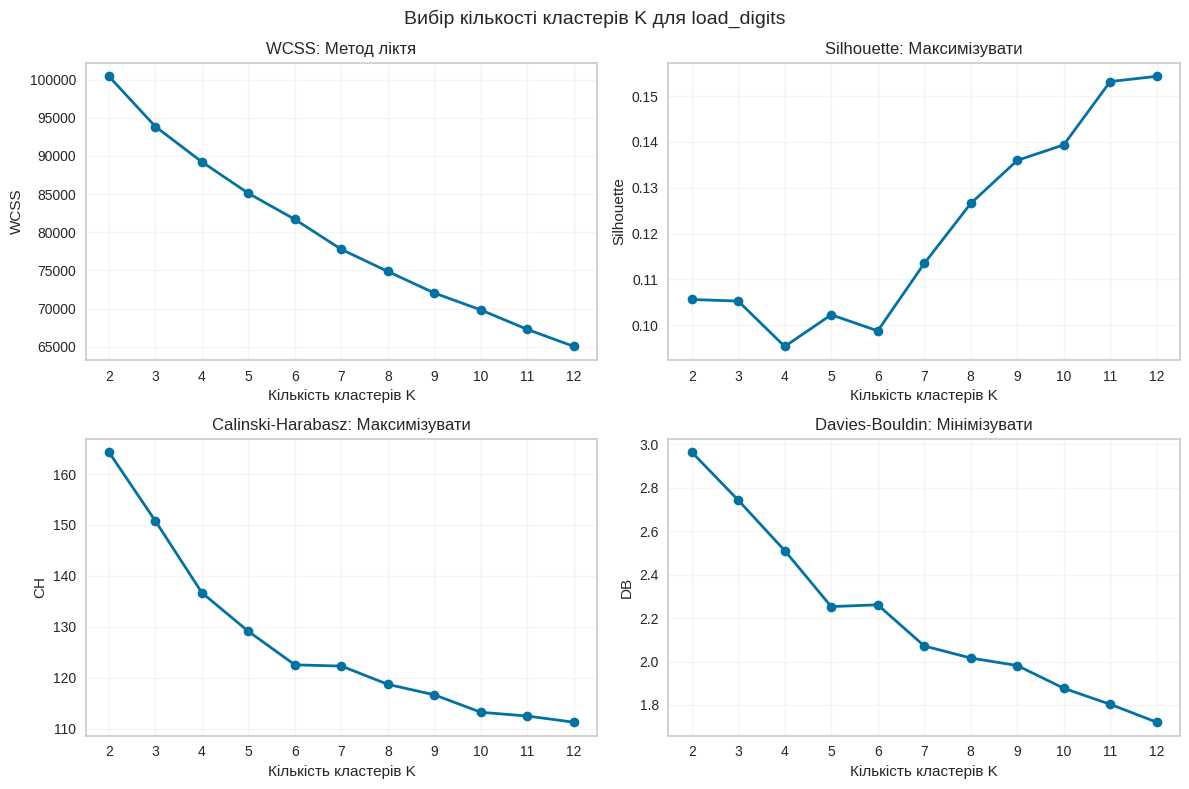

In [94]:
# Візуалізація критеріїв вибору кількості кластерів

fig, axes = plt.subplots(2, 2, figsize = (12, 8))

metrics = ['WCSS', 'Silhouette', 'CH', 'DB']
titles = [
    'WCSS: Метод ліктя',
    'Silhouette: Максимізувати',
    'Calinski-Harabasz: Максимізувати',
    'Davies-Bouldin: Мінімізувати'
]

for ax, metric, title in zip(axes.flat, metrics, titles):
    ax.plot(
        metrics_digits.index,
        metrics_digits[metric],
        marker = 'o',
        linewidth = 2
    )

    ax.set_title(title)
    ax.set_xlabel('Кількість кластерів K')
    ax.set_ylabel(metric)
    ax.set_xticks(metrics_digits.index)

plt.suptitle(
    'Вибір кількості кластерів K для load_digits',
    fontsize = 14
)

plt.tight_layout()
plt.show()

Кандидат за методом ліктя: 7


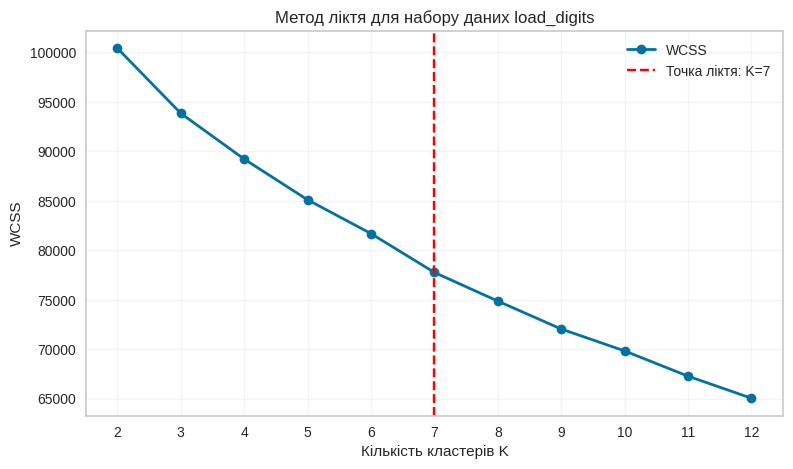

In [95]:
# Автоматичний пошук точки ліктя за допомогою Kneed

from kneed import KneeLocator

knee_digits = KneeLocator(
    metrics_digits.index.to_list(),
    metrics_digits['WCSS'].to_list(),
    curve = 'convex',
    direction = 'decreasing'
)

print("Кандидат за методом ліктя:", knee_digits.elbow)

plt.figure(figsize = (9, 5))

plt.plot(
    metrics_digits.index,
    metrics_digits['WCSS'],
    marker = 'o',
    linewidth = 2,
    label = 'WCSS'
)

if knee_digits.elbow is not None:
    plt.axvline(
        knee_digits.elbow,
        color = 'red',
        linestyle = '--',
        label = f'Точка ліктя: K={knee_digits.elbow}'
    )

plt.title('Метод ліктя для набору даних load_digits')
plt.xlabel('Кількість кластерів K')
plt.ylabel('WCSS')
plt.xticks(metrics_digits.index)
plt.legend()
plt.show()

###**Пояснення:**

За допомогою функції `plt.subplots(2, 2)` із бібліотеки `matplotlib` побудовано чотири графіки залежності критеріїв якості кластеризації від кількості кластерів `K` для набору даних `load_digits`.

Для візуалізації використано попередньо обчислені значення метрик `WCSS`, `Silhouette`, `Calinski–Harabasz` (`CH`) та `Davies–Bouldin` (`DB`) для кількості кластерів від 2 до 12, збережені в таблиці `metrics_digits`.

Додатково за допомогою класу `KneeLocator` із бібліотеки `kneed` виконано автоматичний пошук точки перегину («ліктя») на кривій залежності `WCSS` від кількості кластерів.

Для аналізу використано параметри `curve='convex'` та `direction='decreasing'`, які визначають опуклу спадну форму досліджуваної кривої. Знайдене значення `K` отримано за допомогою атрибута `elbow`.

**Аналіз графіка `WCSS` (метод ліктя):**

На першому графіку спостерігається поступове зменшення значення `WCSS` зі збільшенням кількості кластерів від 2 до 12.

Значення показника знижується від 100423.843 при `K=2` до 65031.724 при `K=12`, що свідчить про зменшення внутрішньокластерного розсіювання зі збільшенням кількості сформованих груп.

Найбільш помітне зниження `WCSS` спостерігається на початкових етапах, після чого крива поступово стає більш пологою.

Водночас чітко виражений перегин візуально визначити складно, тому для його автоматичного пошуку додатково використано інструмент `KneeLocator`.

**Аналіз графіка `Silhouette`:**

На другому графіку відображено залежність середнього коефіцієнта силуету від кількості кластерів.

Найменше значення 0.095 спостерігається при `K=4`, після чого показник загалом зростає та досягає максимального значення 0.154 при `K=12`.

Це свідчить про те, що серед перевірених варіантів найбільш сприятливе співвідношення компактності та відокремленості кластерів за метрикою `Silhouette` отримано при `K=12`.

Водночас навіть максимальне значення коефіцієнта силуету є відносно низьким, що вказує на недостатньо чітке геометричне розмежування сформованих груп у багатовимірному просторі ознак.

**Аналіз графіка `Calinski–Harabasz` (`CH`):**

На третьому графіку спостерігається послідовне зменшення значення індексу `Calinski–Harabasz` зі збільшенням кількості кластерів.

Максимальне значення 164.321 отримано при `K=2`, тоді як при `K=12` показник знижується до 111.253.

Отже, за критерієм `Calinski–Harabasz` найбільш сприятливим є розбиття на два кластери, оскільки воно забезпечує найвище співвідношення міжкластерного та внутрішньокластерного розсіювання серед досліджених варіантів.

**Аналіз графіка `Davies–Bouldin` (`DB`):**

На четвертому графіку спостерігається загальна тенденція до зменшення значення індексу `Davies–Bouldin` зі збільшенням кількості кластерів.

Показник знижується від 2.964 при `K=2` до мінімального значення 1.721 при `K=12`.

Незначне локальне підвищення спостерігається при `K=6`, проте надалі значення індексу продовжує зменшуватися.

Отримані результати свідчать про те, що за критерієм `Davies–Bouldin` найкращим серед перевірених варіантів є `K=12`.

**Аналіз автоматичного пошуку точки ліктя:**

За допомогою класу `KneeLocator` автоматично визначено кандидата `K=7`.

На графіку `WCSS` це значення позначено червоною вертикальною пунктирною лінією, яка проходить через точку з `WCSS` = 77749.328.

До `K=7` зменшення `WCSS` є більш помітним, тоді як після цього значення крива стає відносно пологішою, а подальше збільшення кількості кластерів забезпечує менший виграш у компактності груп.

Отриманий результат демонструє, що `K=7` можна розглядати як компромісний варіант між кількістю кластерів та внутрішньокластерним розсіюванням.

**Порівняння отриманих результатів:**

За результатами аналізу чотирьох критеріїв отримано такі рекомендації:

* WCSS (метод ліктя) – K=7;

* Silhouette – K=12;

* Calinski–Harabasz – K=2;

* Davies–Bouldin – K=12.

Отримані результати демонструють, що критерії оцінювання якості кластеризації не мають єдиної рекомендації щодо оптимальної кількості кластерів.

`Silhouette` та `Davies–Bouldin` надають перевагу більшій кількості груп, `Calinski–Harabasz` – меншій, тоді як метод ліктя пропонує проміжне значення.

Для подальшого дослідження доцільно обрати `K=7` як компромісний варіант, оскільки це значення автоматично визначено методом ліктя та воно дозволяє уникнути надмірного збільшення кількості кластерів.

Водночас значення `Silhouette` при `K=7` становить лише 0.113, що свідчить про недостатньо чітке розмежування груп. Тому вибір `K=7` не означає, що це розбиття є найкращим за всіма критеріями.

###**6. Фінальна кластеризація набору даних load_digits алгоритмом KMeans**

In [96]:
# Фінальна кластеризація набору даних load_digits

k_digits_final = 7

kmeans_digits_final = KMeans(
    n_clusters = k_digits_final,
    n_init = 10,
    random_state = RANDOM_STATE
)

labels_digits_km = kmeans_digits_final.fit_predict(X_digits)

print("Кількість сформованих кластерів:",
      len(np.unique(labels_digits_km)))

print("Розмірність центроїдів:",
      kmeans_digits_final.cluster_centers_.shape)

print("WCSS:", round(kmeans_digits_final.inertia_, 3))

print("Silhouette:",
      round(silhouette_score(X_digits, labels_digits_km), 3))

print("Calinski-Harabasz:",
      round(calinski_harabasz_score(X_digits, labels_digits_km), 3))

print("Davies-Bouldin:",
      round(davies_bouldin_score(X_digits, labels_digits_km), 3))

Кількість сформованих кластерів: 7
Розмірність центроїдів: (7, 64)
WCSS: 77749.328
Silhouette: 0.113
Calinski-Harabasz: 122.28
Davies-Bouldin: 2.072


Розподіл об'єктів за кластерами:


,Кластер,Кількість об’єктів,Частка (%)
0,0,31,1.73
1,1,217,12.08
2,2,452,25.15
3,3,178,9.91
4,4,227,12.63
5,5,249,13.86
6,6,443,24.65


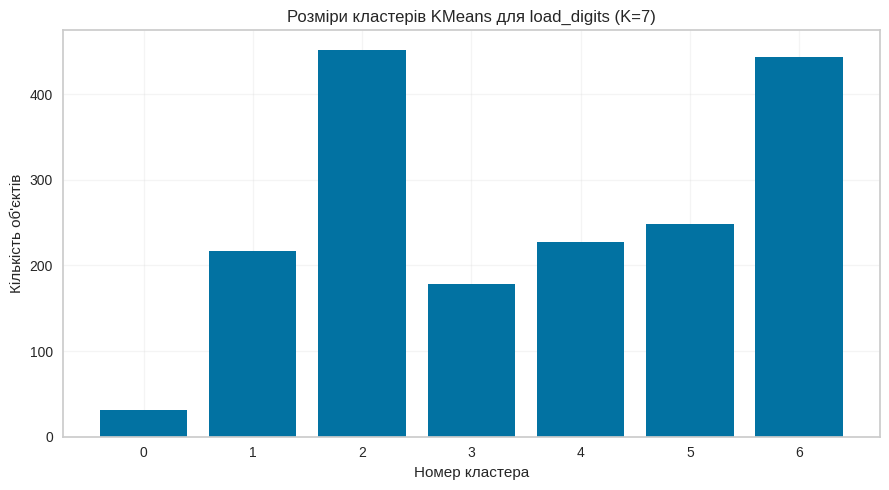

In [97]:
# Аналіз розмірів сформованих кластерів

cluster_sizes_digits = (
    pd.Series(labels_digits_km)
    .value_counts()
    .sort_index()
)

cluster_table_digits = pd.DataFrame({
    'Кластер': cluster_sizes_digits.index,
    'Кількість об’єктів': cluster_sizes_digits.values,
    'Частка (%)': (
        cluster_sizes_digits.values / len(X_digits) * 100
    ).round(2)
})

print("Розподіл об'єктів за кластерами:")
display(cluster_table_digits)

plt.figure(figsize = (9, 5))

plt.bar(
    cluster_sizes_digits.index,
    cluster_sizes_digits.values
)

plt.title('Розміри кластерів KMeans для load_digits (K=7)')
plt.xlabel('Номер кластера')
plt.ylabel("Кількість об'єктів")
plt.xticks(cluster_sizes_digits.index)

plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою класу `KMeans` із бібліотеки `scikit-learn` виконано фінальну кластеризацію набору даних `load_digits` із використанням 1797 об'єктів та 64 попередньо стандартизованих ознак `X_digits`.

Для кластеризації обрано `K=7`, що відповідає результату автоматичного визначення точки ліктя за допомогою `KneeLocator` на попередньому етапі дослідження.

Для навчання моделі використано параметри `n_clusters=7`, `n_init=10` та `random_state=42`, які задають кількість кластерів, десять незалежних ініціалізацій центроїдів та відтворюваність результатів.

За допомогою методу `fit_predict()` виконано навчання алгоритму та визначено належність кожного об'єкта до відповідного кластера.

Для оцінювання якості фінального розбиття обчислено `WCSS` (`inertia_`), `Silhouette` (`silhouette_score`), `Calinski–Harabasz` (`calinski_harabasz_score`) та `Davies–Bouldin` (`davies_bouldin_score`).

Додатково за допомогою функції `np.unique()` визначено кількість сформованих кластерів, а атрибут `cluster_centers_.shape` використано для перевірки розмірності масиву центроїдів.

Для аналізу розподілу об'єктів між кластерами застосовано методи `value_counts()` та `sort_index()`, які дозволяють обчислити кількість об'єктів у кожній групі та впорядкувати результати за номерами кластерів.

Частку об'єктів у кожному кластері визначено як відношення кількості об'єктів відповідної групи до загальної кількості спостережень.

За допомогою функції `plt.bar()` побудовано стовпчикову діаграму розмірів сформованих кластерів.

**Аналіз результатів фінальної кластеризації:**

У результаті виконання алгоритму `KMeans` сформовано 7 кластерів, що відповідає попередньо вибраному значенню `K=7`.

Розмірність масиву центроїдів становить (7, 64), що підтверджує наявність семи центрів кластерів, кожен із яких описується 64 стандартизованими ознаками.

**Отримано такі значення критеріїв якості кластеризації:**

* WCSS = 77749.328;

* Silhouette = 0.113;

* Calinski–Harabasz = 122.280;

* Davies–Bouldin = 2.072.

Значення `WCSS` характеризує суму квадратів відстаней об'єктів до відповідних центроїдів, а отриманий показник узгоджується з результатами попереднього дослідження для `K=7`.

Відносно низьке значення `Silhouette = 0.113` свідчить про недостатньо чітку відокремленість сформованих кластерів та можливе перекриття груп у багатовимірному просторі ознак.

Показники `Calinski–Harabasz` та `Davies–Bouldin` також відповідають попереднім результатам для семи кластерів і можуть використовуватися для порівняння з альтернативними розбиттями.

**Аналіз розподілу об'єктів за кластерами:**

У результаті кластеризації отримано такі розміри сформованих груп:

* Кластер 0 – 31 об'єкт (1.73%);

* Кластер 1 – 217 об'єктів (12.08%);

* Кластер 2 – 452 об'єкти (25.15%);

* Кластер 3 – 178 об'єктів (9.91%);

* Кластер 4 – 227 об'єктів (12.63%);

* Кластер 5 – 249 об'єктів (13.86%);

* Кластер 6 – 443 об'єкти (24.65%).

Отримані результати демонструють нерівномірний розподіл об'єктів між сімома кластерами.

Найбільшими є кластер 2 (452 об'єкти) та кластер 6 (443 об'єкти), які разом охоплюють майже половину всього набору даних.

Натомість найменшим є кластер 0, який містить лише 31 об'єкт (1.73%). Це свідчить про виділення невеликої групи спостережень, що за своїми числовими характеристиками відрізняються від інших сформованих кластерів.

Інші кластери мають проміжні розміри – від 178 до 249 об'єктів.

**Аналіз стовпчикової діаграми:**

На графіку відображено кількість об'єктів у кожному з семи кластерів, сформованих алгоритмом `KMeans`.

Найвищі стовпчики відповідають кластерам 2 та 6, що підтверджує їхнє переважання за кількістю спостережень.

Найнижчий стовпчик відповідає кластеру 0, розмір якого суттєво менший порівняно з іншими групами.

Кластери 1, 3, 4 та 5 мають відносно близькі розміри, проте загальний розподіл залишається нерівномірним.

Це демонструє, що алгоритм `KMeans` не забезпечує однакову кількість об'єктів у кожному кластері, а формує групи відповідно до розташування спостережень у просторі ознак та відстаней до центроїдів.

###**7. Порівняння алгоритмів KMeans та AgglomerativeClustering (Ward)**

In [98]:
# Кластеризація набору даних load_digits методом Ward

ward_digits = AgglomerativeClustering(
    n_clusters = k_digits_final,
    linkage = 'ward'
)

labels_digits_ward = ward_digits.fit_predict(X_digits)

print("Кількість сформованих кластерів:",
      len(np.unique(labels_digits_ward)))

print("Silhouette:",
      round(silhouette_score(X_digits, labels_digits_ward), 3))

print("Calinski-Harabasz:",
      round(calinski_harabasz_score(X_digits, labels_digits_ward), 3))

print("Davies-Bouldin:",
      round(davies_bouldin_score(X_digits, labels_digits_ward), 3))

print("ARI між KMeans та Ward:",
      round(adjusted_rand_score(
          labels_digits_km, labels_digits_ward
      ), 3))

Кількість сформованих кластерів: 7
Silhouette: 0.096
Calinski-Harabasz: 108.242
Davies-Bouldin: 2.198
ARI між KMeans та Ward: 0.476


Порівняння якості кластеризації:


,Алгоритм,Кількість кластерів,Silhouette,CH,DB
0,KMeans,7,0.113,122.280,2.072
1,Ward,7,0.096,108.242,2.198



Розміри кластерів:


,KMeans,Ward
0,31,714
1,217,195
2,452,169
3,178,40
4,227,319
5,249,178
6,443,182


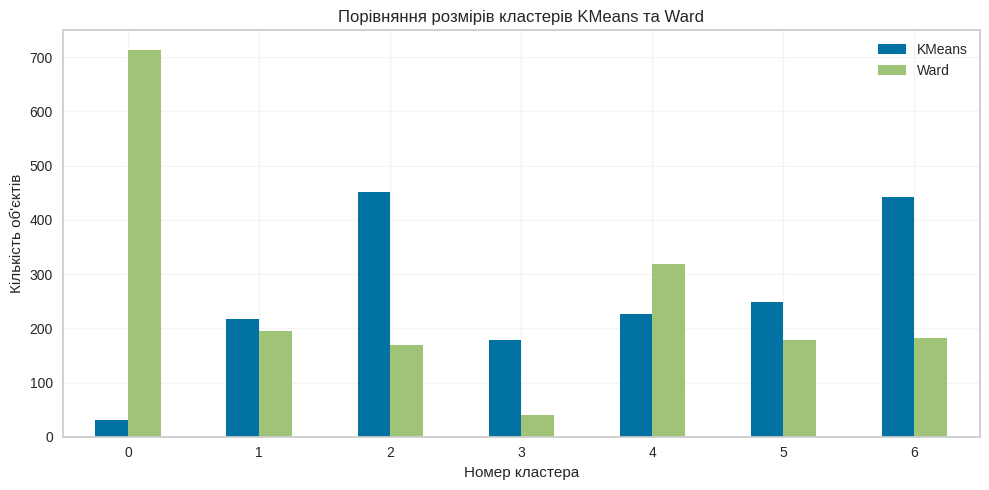

In [99]:
# Порівняння результатів KMeans та Ward

comparison_digits = pd.DataFrame([
    {
        'Алгоритм': 'KMeans',
        'Кількість кластерів': len(np.unique(labels_digits_km)),
        'Silhouette': silhouette_score(
            X_digits, labels_digits_km
        ),
        'CH': calinski_harabasz_score(
            X_digits, labels_digits_km
        ),
        'DB': davies_bouldin_score(
            X_digits, labels_digits_km
        )
    },
    {
        'Алгоритм': 'Ward',
        'Кількість кластерів': len(np.unique(labels_digits_ward)),
        'Silhouette': silhouette_score(
            X_digits, labels_digits_ward
        ),
        'CH': calinski_harabasz_score(
            X_digits, labels_digits_ward
        ),
        'DB': davies_bouldin_score(
            X_digits, labels_digits_ward
        )
    }
])

print("Порівняння якості кластеризації:")
display(comparison_digits.round(3))

sizes_comparison = pd.DataFrame({
    'KMeans': pd.Series(labels_digits_km)
        .value_counts().sort_index(),
    'Ward': pd.Series(labels_digits_ward)
        .value_counts().sort_index()
})

print("\nРозміри кластерів:")
display(sizes_comparison)

sizes_comparison.plot(
    kind = 'bar',
    figsize = (10, 5)
)

plt.title('Порівняння розмірів кластерів KMeans та Ward')
plt.xlabel('Номер кластера')
plt.ylabel("Кількість об'єктів")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою класу `AgglomerativeClustering` із бібліотеки `scikit-learn` виконано ієрархічну агломеративну кластеризацію набору даних `load_digits` із використанням 1797 об'єктів та 64 попередньо стандартизованих ознак `X_digits`.

Для кластеризації використано метод `Ward` із параметрами `n_clusters=7` та `linkage='ward'`. Метод `Ward` передбачає послідовне об'єднання кластерів таким чином, щоб приріст внутрішньокластерної суми квадратів відхилень був мінімальним.

За допомогою методу `fit_predict()` виконано навчання алгоритму та визначено належність кожного об'єкта до відповідного кластера.

Для оцінювання якості отриманого розбиття обчислено три внутрішні метрики: `Silhouette` (`silhouette_score`), `Calinski–Harabasz` (`calinski_harabasz_score`) та `Davies–Bouldin` (`davies_bouldin_score`).

Додатково за допомогою функції `adjusted_rand_score()` обчислено `Adjusted Rand Index` (`ARI`) між результатами алгоритмів `KMeans` та `Ward`, що дозволяє оцінити ступінь узгодженості двох кластерних розбиттів незалежно від числових позначень кластерів.

Для порівняння результатів створено таблицю `comparison_digits`, яка містить кількість кластерів та значення трьох метрик якості для обох алгоритмів.

За допомогою методів `value_counts()` та `sort_index()` визначено кількість об'єктів у кожному кластері, а функцією `plot(kind='bar')` побудовано стовпчикову діаграму розмірів кластерів `KMeans` та `Ward`.

**Аналіз результатів кластеризації методом `Ward`:**

У результаті застосування алгоритму `AgglomerativeClustering` сформовано 7 кластерів, що відповідає попередньо обраній кількості груп `K=7`.

**Отримано такі значення критеріїв якості кластеризації:**

* Silhouette = 0.096;

* Calinski–Harabasz = 108.242;

* Davies–Bouldin = 2.198.

Відносно низьке значення `Silhouette` свідчить про недостатньо чітку відокремленість сформованих кластерів та можливе перекриття груп у багатовимірному просторі ознак.

Значення `Calinski–Harabasz` та `Davies–Bouldin` характеризують співвідношення міжкластерного й внутрішньокластерного розсіювання та дозволяють порівняти результати методу `Ward` з алгоритмом `KMeans`.

**Порівняння якості алгоритмів `KMeans` та `Ward`:**

За результатами обчислень алгоритм `KMeans` отримав значення `Silhouette` 0.113, тоді як метод `Ward` – 0.096.

Це свідчить про дещо кращу компактність та відокремленість кластерів `KMeans` за метрикою `Silhouette`.

Показник `Calinski–Harabasz` також є вищим для `KMeans` (122.280) порівняно з `Ward` (108.242), що вказує на більш сприятливе співвідношення міжкластерного та внутрішньокластерного розсіювання.

Водночас значення `Davies–Bouldin` для `KMeans` становить 2.072, а для `Ward` – 2.198. Оскільки менше значення цього показника є кращим, `KMeans` також має перевагу за даним критерієм.

Отже, алгоритм `KMeans` продемонстрував кращі результати за всіма трьома внутрішніми метриками якості кластеризації серед двох досліджених алгоритмів для `K=7`.

**Аналіз узгодженості результатів за метрикою `ARI`:**

У результаті порівняння кластерних розбиттів `KMeans` та `Ward` отримано значення `ARI` = 0.476.

Це свідчить про помірну узгодженість результатів двох алгоритмів, тобто частина об'єктів об'єднується в аналогічні групи, проте структура сформованих кластерів помітно відрізняється.

Отриманий показник підтверджує, що алгоритми `KMeans` та `Ward` можуть формувати різні розбиття навіть за однакової кількості кластерів та використання тих самих стандартизованих даних.

При цьому `ARI` характеризує лише подібність двох кластерних розбиттів і не визначає, який алгоритм точніше відтворює справжні класи рукописних цифр.

**Аналіз розмірів сформованих кластерів:**

У результаті застосування алгоритму `KMeans` отримано сім кластерів із кількістю об'єктів 31, 217, 452, 178, 227, 249 та 443.

Найбільшими є кластери 2 та 6, які містять 452 та 443 об'єкти відповідно, тоді як найменший кластер 0 містить лише 31 об'єкт.

Для алгоритму `Ward` отримано кластери з кількістю об'єктів 714, 195, 169, 40, 319, 178 та 182.

Найбільшим є кластер 0 (714 об'єктів), який охоплює приблизно 39.7% усього набору даних.

Найменшим є кластер 3 (40 об'єктів), що становить приблизно 2.2% від загальної кількості спостережень.

Отримані результати свідчать про нерівномірний розподіл об'єктів між кластерами в обох алгоритмах, проте для методу `Ward` спостерігається особливо велика концентрація спостережень в одному кластері.

**Аналіз стовпчикової діаграми:**

На графіку відображено кількість об'єктів у кожному з семи кластерів, сформованих алгоритмами `KMeans` та `Ward`.

Для `KMeans` (сині стовпчики) найбільша кількість об'єктів спостерігається у кластерах 2 та 6, тоді як кластер 0 є найменшим.

Для `Ward` (зелені стовпчики) найбільшим є кластер 0, який суттєво перевищує за розміром інші групи, а найменшим – кластер 3.

Спостерігаються значні відмінності між розмірами кластерів двох алгоритмів, що свідчить про різні принципи групування об'єктів.

Водночас необхідно враховувати, що номери кластерів є умовними, тому однакові номери в результатах `KMeans` та `Ward` не обов'язково відповідають однаковим групам об'єктів.

###**8. Візуалізація результатів кластеризації методом PCA**

Розмірність даних після PCA: (1797, 2)
Частка поясненої дисперсії:
[0.12  0.096]
Сумарна частка поясненої дисперсії: 0.216


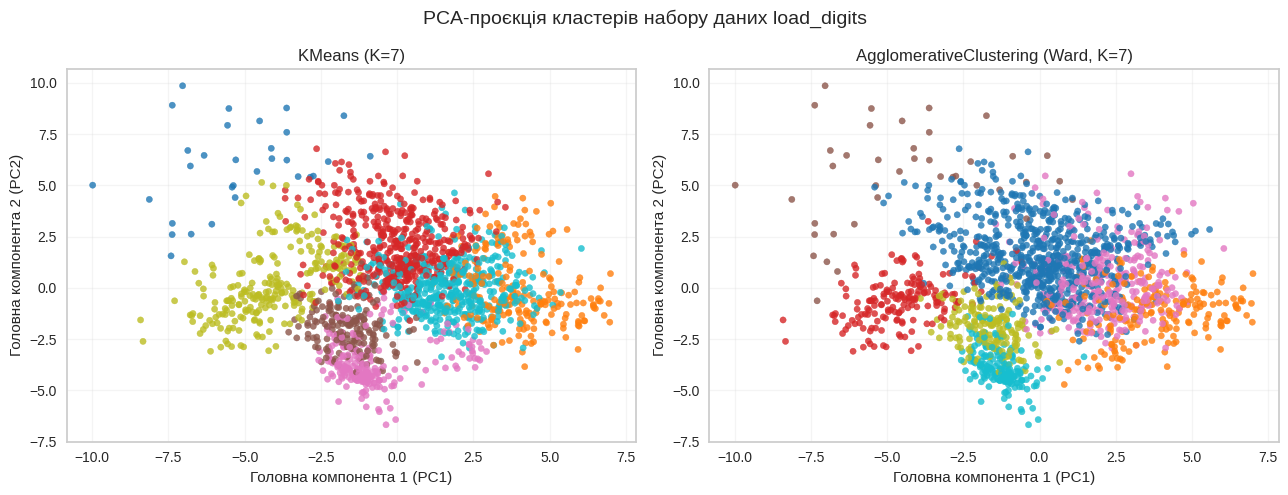

In [100]:
# Візуалізація результатів кластеризації методом PCA

pca_digits = PCA(
    n_components = 2,
    random_state = RANDOM_STATE
)

X_digits_2d = pca_digits.fit_transform(X_digits)

print("Розмірність даних після PCA:", X_digits_2d.shape)

print("Частка поясненої дисперсії:")
print(np.round(pca_digits.explained_variance_ratio_, 3))

print("Сумарна частка поясненої дисперсії:",
      round(pca_digits.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, labels, name in zip(
    axes,
    [labels_digits_km, labels_digits_ward],
    ['KMeans (K=7)', 'AgglomerativeClustering (Ward, K=7)']
):
    ax.scatter(
        X_digits_2d[:, 0],
        X_digits_2d[:, 1],
        c = labels,
        cmap = 'tab10',
        s = 20,
        alpha = 0.8
    )

    ax.set_title(name)
    ax.set_xlabel('Головна компонента 1 (PC1)')
    ax.set_ylabel('Головна компонента 2 (PC2)')

plt.suptitle(
    'PCA-проєкція кластерів набору даних load_digits',
    fontsize = 14
)

plt.tight_layout()
plt.show()

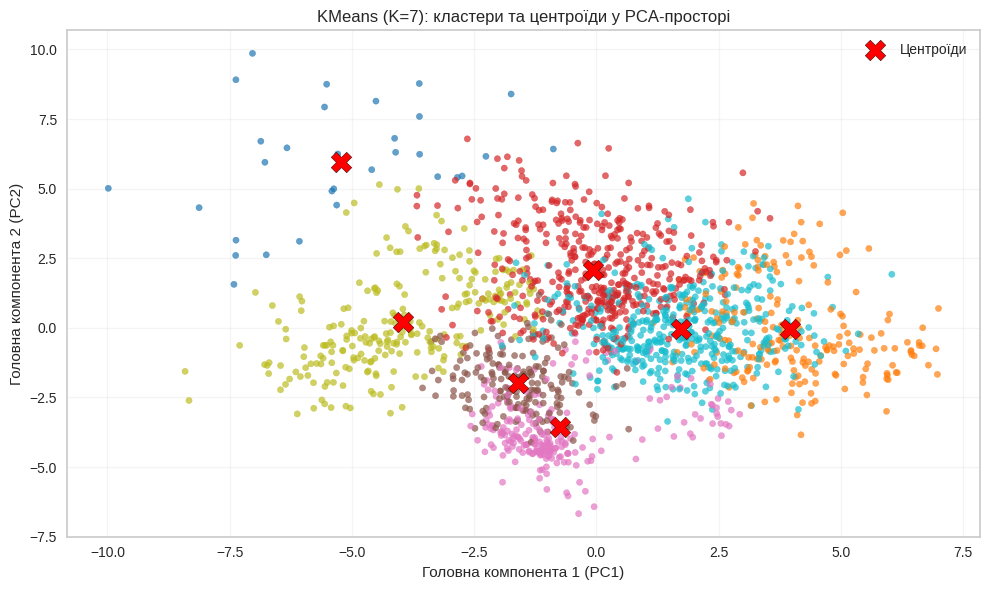

In [101]:
# Візуалізація центроїдів KMeans у PCA-просторі

centers_digits_2d = pca_digits.transform(
    kmeans_digits_final.cluster_centers_
)

plt.figure(figsize = (10, 6))

plt.scatter(
    X_digits_2d[:, 0],
    X_digits_2d[:, 1],
    c = labels_digits_km,
    cmap = 'tab10',
    s = 20,
    alpha = 0.7
)

plt.scatter(
    centers_digits_2d[:, 0],
    centers_digits_2d[:, 1],
    color = 'red',
    marker = 'X',
    s = 220,
    edgecolors = 'black',
    label = 'Центроїди'
)

plt.title('KMeans (K=7): кластери та центроїди у PCA-просторі')
plt.xlabel('Головна компонента 1 (PC1)')
plt.ylabel('Головна компонента 2 (PC2)')
plt.legend()

plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою класу `PCA` із бібліотеки `scikit-learn` виконано зменшення розмірності набору даних `load_digits` із 64 стандартизованих ознак до двох головних компонент для візуалізації результатів кластеризації.

Для створення моделі використано параметри `n_components=2` та `random_state=42`. За допомогою методу `fit_transform()` виконано перетворення стандартизованих даних `X_digits` у двовимірний простір головних компонент `PC1` та `PC2`.

Для оцінювання інформативності отриманої проєкції використано атрибут `explained_variance_ratio_`, який визначає частку загальної дисперсії даних, що пояснюється кожною головною компонентою.

За допомогою функцій `plt.subplots()` та `scatter()` із бібліотеки `matplotlib` побудовано два графіки розсіювання, які відображають результати кластеризації алгоритмами `KMeans` та `AgglomerativeClustering` (`Ward`) у спільному двовимірному просторі.

Кольорами позначено належність об'єктів до відповідних кластерів, визначену раніше за допомогою алгоритмів `KMeans` та `Ward` із кількістю кластерів `K=7`.

Додатково за допомогою методу `pca_digits.transform()` виконано перетворення центроїдів `KMeans` із 64-вимірного простору до двовимірного `PCA`-простору.

Для візуалізації побудовано окремий графік, на якому центроїди семи кластерів позначено червоними хрестиками з чорними контурами, а об'єкти різних груп – окремими кольорами.

**Аналіз результатів зменшення розмірності:**

У результаті застосування методу `PCA` отримано розмірність даних (1797, 2), що підтверджує перетворення початкових 64 ознак на дві головні компоненти без зміни кількості об'єктів.

Частка поясненої дисперсії для першої головної компоненти `PC1` становить 0.120 (12.0%), а для другої компоненти `PC2` – 0.096 (9.6%).

Сумарна частка поясненої дисперсії становить 0.216 (21.6%), тобто перші дві головні компоненти зберігають лише частину загальної мінливості початкових даних.

Це свідчить про те, що двовимірна `PCA`-проєкція не відображає всієї інформації, яка міститься у 64-вимірному просторі ознак, тому результати візуалізації необхідно інтерпретувати з урахуванням втрати значної частини дисперсії.

**Аналіз `PCA`-проєкції `KMeans`:**

На першому графіку відображено результати кластеризації набору даних `load_digits` алгоритмом `KMeans` (`K=7`).

Спостерігається формування семи груп об'єктів, які займають різні області двовимірного простору головних компонент.

Окремі кластери мають відносно виражене просторове розташування. Зокрема, у лівій частині графіка помітна група об'єктів із від'ємними значеннями `PC1`, а в нижній центральній частині – компактніші групи з від'ємними значеннями `PC2`.

Водночас у центральній та правій частинах графіка спостерігається значне перекриття об'єктів різних кластерів, що свідчить про недостатньо чітке їх розмежування у двовимірній проєкції.

Отримана структура узгоджується з відносно низьким значенням `Silhouette` = 0.113, отриманим раніше для алгоритму `KMeans`.

**Аналіз `PCA`-проєкції `Ward`:**

На другому графіку відображено результати ієрархічної агломеративної кластеризації методом `Ward` (`K=7`).

Алгоритм також сформував сім груп, проте їхнє просторове розташування та розподіл об'єктів помітно відрізняються від результатів KMeans.

Зокрема, у центральній частині графіка спостерігається велика група об'єктів, яка частково перекривається з іншими кластерами.

Окремі групи розташовані переважно в лівій нижній, центральній нижній та правій частинах `PCA`-простору, проте їхні межі не завжди є чіткими.

Значне перекриття кластерів узгоджується з отриманим раніше значенням `Silhouette` = 0.096, яке є нижчим порівняно з `KMeans`.

**Порівняння `PCA`-проєкцій `KMeans` та `Ward`:**

Обидва алгоритми сформували по сім кластерів на основі однакових 64 стандартизованих ознак, проте отримані розбиття мають різну просторову структуру.

Для `KMeans` спостерігається дещо чіткіше розташування окремих груп, тоді як для `Ward` характерна більша концентрація об'єктів у центральній області `PCA`-проєкції.

Водночас на обох графіках помітне перекриття кластерів, що підтверджує складність групування рукописних цифр за їхніми піксельними характеристиками.

Отримані відмінності узгоджуються з попереднім значенням `ARI` = 0.476, яке свідчить про помірну узгодженість кластерних розбиттів `KMeans` та `Ward`.

При цьому однакові кольори на двох графіках не обов'язково відповідають однаковим групам об'єктів, оскільки номери кластерів визначаються алгоритмами незалежно.

**Аналіз графіка центроїдів `KMeans` у `PCA`-просторі:**

На третьому графіку відображено результати кластеризації `KMeans` із позначенням семи центроїдів, перетворених у двовимірний простір головних компонент.

Червоні хрестики розташовані поблизу центральних областей відповідних груп, що відображає положення центрів кластерів після проєктування.

Спостерігається, що частина центроїдів достатньо віддалена один від одного, зокрема в лівій верхній та нижній центральній частинах графіка.

Водночас декілька центроїдів у центральній та правій частинах розташовані відносно близько, а відповідні групи частково перекриваються.

Це демонструє, що деякі кластери мають подібні характеристики у двовимірному `PCA`-просторі, хоча їхнє формування здійснювалося на основі всіх 64 стандартизованих ознак.

###**9. Зовнішнє оцінювання результатів кластеризації**

In [102]:
# Зовнішнє оцінювання результатів кластеризації

y_digits_reference = digits.target

ari_digits_km = adjusted_rand_score(
    y_digits_reference,
    labels_digits_km
)

ari_digits_ward = adjusted_rand_score(
    y_digits_reference,
    labels_digits_ward
)

print("Кількість еталонних класів:",
      len(np.unique(y_digits_reference)))

print("Кількість кластерів KMeans:",
      len(np.unique(labels_digits_km)))

print("Кількість кластерів Ward:",
      len(np.unique(labels_digits_ward)))

print("\nARI KMeans до еталонних міток:",
      round(ari_digits_km, 3))

print("ARI Ward до еталонних міток:",
      round(ari_digits_ward, 3))

Кількість еталонних класів: 10
Кількість кластерів KMeans: 7
Кількість кластерів Ward: 7

ARI KMeans до еталонних міток: 0.382
ARI Ward до еталонних міток: 0.424


Порівняння алгоритмів за метрикою ARI:


,Алгоритм,Кількість кластерів,ARI
0,KMeans,7,0.382
1,Ward,7,0.424


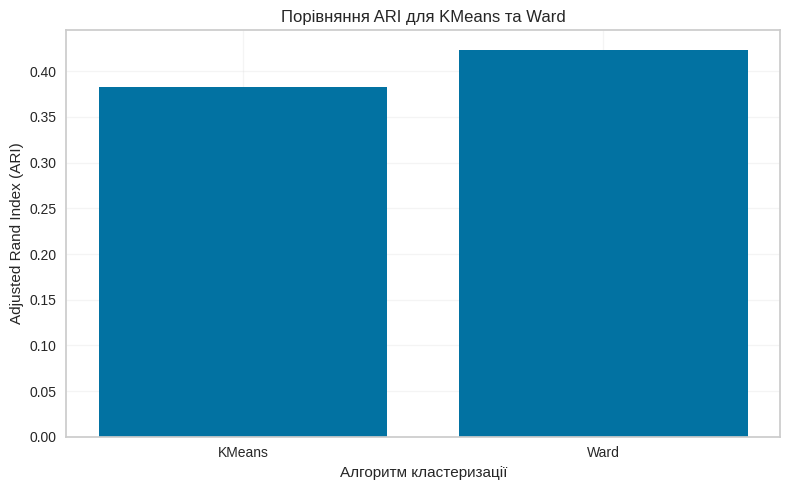

In [103]:
# Порівняння зовнішньої якості кластеризації

ari_comparison_digits = pd.DataFrame({
    'Алгоритм': ['KMeans', 'Ward'],
    'Кількість кластерів': [
        len(np.unique(labels_digits_km)),
        len(np.unique(labels_digits_ward))
    ],
    'ARI': [
        ari_digits_km,
        ari_digits_ward
    ]
})

print("Порівняння алгоритмів за метрикою ARI:")
display(ari_comparison_digits.round(3))

plt.figure(figsize = (8, 5))

plt.bar(
    ari_comparison_digits['Алгоритм'],
    ari_comparison_digits['ARI']
)

plt.title('Порівняння ARI для KMeans та Ward')
plt.xlabel('Алгоритм кластеризації')
plt.ylabel('Adjusted Rand Index (ARI)')

plt.tight_layout()
plt.show()

Розподіл справжніх цифр за кластерами KMeans:


Справжня цифра,0,1,2,3,4,5,6,7,8,9
Кластер KMeans,,,,,,,,,,
0,0,0,0,0,9,0,0,18,0,4
1,0,3,139,11,0,46,0,6,12,0
2,0,96,16,14,15,55,1,151,89,15
3,176,0,1,0,0,0,1,0,0,0
4,0,25,7,1,0,2,179,0,12,1
5,2,58,5,0,157,4,0,4,4,15
6,0,0,9,157,0,75,0,0,57,145


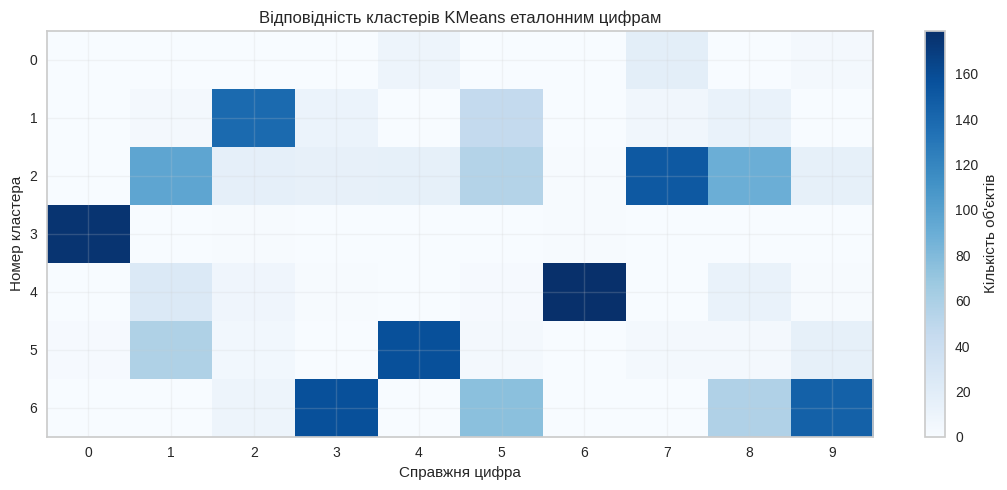

In [104]:
# Аналіз відповідності кластерів еталонним класам

cluster_class_table = pd.crosstab(
    pd.Series(labels_digits_km, name = 'Кластер KMeans'),
    pd.Series(y_digits_reference, name = 'Справжня цифра')
)

print("Розподіл справжніх цифр за кластерами KMeans:")
display(cluster_class_table)

plt.figure(figsize = (11, 5))

plt.imshow(cluster_class_table.values, cmap = 'Blues', aspect = 'auto')
plt.colorbar(label = "Кількість об'єктів")

plt.xticks(
    range(cluster_class_table.shape[1]),
    cluster_class_table.columns
)

plt.yticks(
    range(cluster_class_table.shape[0]),
    cluster_class_table.index
)

plt.title('Відповідність кластерів KMeans еталонним цифрам')
plt.xlabel('Справжня цифра')
plt.ylabel('Номер кластера')

plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою атрибута `digits.target` отримано еталонні мітки рукописних цифр із набору даних `load_digits`, які використано для незалежного оцінювання результатів кластеризації після завершення навчання моделей `KMeans` та `AgglomerativeClustering` (`Ward`).

Для порівняння отриманих кластерів зі справжніми класами використано метрику `Adjusted Rand Index` (`adjusted_rand_score`), яка оцінює ступінь узгодженості двох розбиттів на основі пар об'єктів із поправкою на випадкові збіги.

За допомогою функції `np.unique()` визначено кількість еталонних класів та кількість кластерів, сформованих кожним алгоритмом.

Для наочного порівняння результатів створено таблицю `ari_comparison_digits`, яка містить назви алгоритмів, кількість сформованих кластерів та отримані значення `ARI`.

За допомогою функції `plt.bar()` побудовано стовпчикову діаграму порівняння `ARI` для `KMeans` та `Ward`.

Додатково за допомогою функції `pd.crosstab()` створено таблицю відповідності між номерами кластерів KMeans та справжніми класами рукописних цифр.

Для візуалізації цієї таблиці використано функцію `plt.imshow()` із параметром `cmap='Blues'`, яка дозволяє побудувати теплову карту розподілу еталонних цифр за сформованими кластерами.

**Аналіз отриманих результатів:**

У результаті виконання коду встановлено, що набір даних `load_digits` містить 10 еталонних класів, які відповідають рукописним цифрам від 0 до 9.

Водночас алгоритми `KMeans` та `Ward` сформували по 7 кластерів, відповідно до значення `K=7`, обраного раніше за допомогою методу ліктя.

За результатами зовнішнього оцінювання отримано такі значення:

* ARI KMeans = 0.382;

* ARI Ward = 0.424.

Отримані додатні значення `ARI` свідчать про наявність помітної, але неповної узгодженості сформованих кластерів зі справжніми класами рукописних цифр.

Алгоритм `Ward` отримав вище значення `ARI` (0.424) порівняно з `KMeans` (0.382), що свідчить про кращу відповідність його кластерного розбиття еталонним класам за цією метрикою.

Водночас жоден із алгоритмів не забезпечив повного відтворення справжніх класів, оскільки отримані значення `ARI` суттєво нижчі за 1.

**Аналіз стовпчикової діаграми `ARI`:**

На графіку відображено результати порівняння алгоритмів `KMeans` та `Ward` за метрикою `Adjusted Rand Index`.

Стовпчик алгоритму `Ward` є дещо вищим порівняно з `KMeans`, що підтверджує його перевагу за рівнем узгодженості з еталонними мітками.

Різниця між значеннями `ARI` становить 0.042, тому перевага `Ward` є помірною, проте помітною.

Цей результат відрізняється від попереднього порівняння за внутрішніми метриками, де `KMeans` отримав кращі значення `Silhouette`, `Calinski–Harabasz` та `Davies–Bouldin`.

Отже, краща геометрична компактність та відокремленість кластерів не обов'язково означає кращу відповідність сформованих груп справжнім класам об'єктів.

**Аналіз таблиці відповідності кластерів еталонним цифрам:**

За допомогою таблиці `cluster_class_table` визначено кількість зображень кожної справжньої цифри у семи кластерах, сформованих алгоритмом `KMeans`.

Спостерігається, що окремі кластери переважно містять зображення однієї цифри, тоді як інші об'єднують декілька різних класів.

Кластер 0 містить лише 31 об'єкт, серед яких найбільшу кількість становлять зображення цифри 7 (18 об'єктів). Також до нього потрапили зображення цифр 4 та 9.

Кластер 1 містить переважно зображення цифри 2 (139 об'єктів), проте також включає значну кількість цифр 5 та окремі зображення інших класів.

Кластер 2 є одним із найбільших та характеризується змішаним складом. Найбільше об'єктів відповідає цифрам 7 (151), 1 (96), 8 (89) та 5 (55).

Кластер 3 містить 176 зображень цифри 0 із 178 об'єктів, що свідчить про дуже високу однорідність цієї групи.

Кластер 4 переважно складається із зображень цифри 6 (179 об'єктів), хоча також включає окремі зображення інших цифр.

Кластер 5 характеризується переважанням цифри 4 (157 об'єктів), але також містить зображення цифри 1 та інших класів.

Кластер 6 має змішаний склад, у якому найбільшу кількість становлять зображення цифр 3 (157), 9 (145), 5 (75) та 8 (57).

Отримані результати демонструють, що частина цифр утворює відносно однорідні кластери, тоді як інші об'єднуються у спільні групи через подібність їхніх піксельних характеристик.

**Аналіз теплової карти відповідності кластерів:**

На тепловій карті відображено розподіл справжніх цифр від 0 до 9 між сімома кластерами алгоритму KMeans.

По горизонтальній осі розташовано еталонні класи цифр, а по вертикальній – номери сформованих кластерів.

Інтенсивність синього кольору відповідає кількості об'єктів певного класу в конкретному кластері: чим темніша клітинка, тим більше відповідних зображень належить до цієї групи.

Найбільш виражені темні області спостерігаються для цифри 0 у кластері 3, цифри 6 у кластері 4, цифри 4 у кластері 5 та цифри 2 у кластері 1.

Це свідчить про те, що зазначені цифри мають достатньо характерні піксельні ознаки, які дозволили алгоритму `KMeans` відносно успішно виділити їх в окремі групи.

Водночас для кластерів 2 та 6 спостерігається декілька областей підвищеної інтенсивності, що підтверджує їхній змішаний склад.

Також помітно, що зображення окремих цифр розподіляються між кількома кластерами, тобто алгоритм не завжди об'єднує всі зразки одного класу в єдину групу.

**Пояснення невідповідності кількості кластерів кількості цифр:**

Алгоритми кластеризації працюють за принципом навчання без учителя, тому під час групування об'єктів не використовують інформацію про справжні класи рукописних цифр.

У дослідженні кількість кластерів `K=7` обрано на основі внутрішніх критеріїв якості, а не відповідно до десяти еталонних класів.

Крім того, різні рукописні цифри можуть мати схожі геометричні характеристики, зокрема форму окремих штрихів, нахил та розташування пікселів. Водночас одна й та сама цифра може мати різні варіанти написання, що впливає на відстані між її зображеннями в багатовимірному просторі ознак.

Тому отримані кластери не обов'язково відповідають десяти справжнім класам, а відображають групи об'єктів зі схожими числовими характеристиками.

###**Підсумковий висновок:**

У ході виконання самостійного завдання було проведено повний цикл кластеризації набору даних `load_digits`, який містить 1797 зображень рукописних цифр, представлених 64 числовими ознаками.

На початковому етапі досліджено структуру даних, перевірено відсутність пропущених значень та виконано стандартизацію ознак за допомогою `StandardScaler`.

Для визначення оптимальної кількості кластерів досліджено алгоритм `KMeans` у діапазоні `K=2…12` з використанням критеріїв `WCSS`, `Silhouette`, `Calinski–Harabasz` та `Davies–Bouldin`.

Отримані результати виявили розбіжності між критеріями: `Silhouette` та `Davies–Bouldin` рекомендували `K=12`, `Calinski–Harabasz` – `K=2`, тоді як автоматичний пошук точки ліктя за допомогою `KneeLocator` визначив `K=7`, яке було обрано як компромісний варіант для подальшого дослідження.

За результатами фінальної кластеризації алгоритмом `KMeans` сформовано сім нерівномірних за розміром кластерів зі значенням `Silhouette` 0.113, що свідчить про недостатньо чітке геометричне розмежування груп.

Порівняння з алгоритмом `AgglomerativeClustering` (`Ward`) показало перевагу `KMeans` за всіма трьома внутрішніми метриками, тоді як значення `ARI` = 0.476 між двома розбиттями підтвердило їхню помірну узгодженість.

За допомогою методу головних компонент `PCA` виконано двовимірну візуалізацію результатів кластеризації, яка продемонструвала часткове перекриття сформованих груп, причому перші дві компоненти пояснили лише 21.6% загальної дисперсії даних.

Після завершення кластеризації проведено незалежне зовнішнє оцінювання за еталонними мітками цифр, у результаті якого алгоритм `Ward` отримав вище значення `ARI` (0.424) порівняно з `KMeans` (0.382).

Аналіз таблиці відповідності кластерів справжнім класам показав, що деякі цифри, зокрема 0, 2, 4 та 6, утворюють відносно однорідні групи, тоді як інші класи частково змішуються через подібність піксельних характеристик.

Встановлено, що внутрішні та зовнішні критерії оцінювання можуть надавати різні результати, оскільки геометрична компактність кластерів не гарантує їхньої відповідності справжнім класам.

Таким чином, виконане дослідження продемонструвало можливості та обмеження алгоритмів кластеризації для аналізу зображень рукописних цифр і підтвердило важливість комплексного оцінювання результатів без використання еталонних міток під час вибору кількості кластерів та навчання моделей.